# Bayesian syllable-level decipherment of the Voynich Manuscript

## From the syllabic fingerprint to inter-linguistic mapping

### Part V — Bayesian syllable-level decipherment

**Context**: The previous notebook (Part IV) established:
- A canonical inventory of ~2,923 syllabic types (~200 functional) in 4 positional classes
- 27 root-suffix paradigms with Gini = 0.49
- Nuclear-coda harmony V = 0.284
- Glyphs are already syllabic units (MI does not amplify: 0.92×)

**Question**: With which candidate language are these constraints most compatible?

**Algorithm**: Bayesian decipherment adapted from Ravi & Knight (2011), operating at the syllable level with positional class constraints. Three phases:
1. **Distributional initialisation** — clustering + Hungarian assignment
2. **EM** — E-step (expected bigram counts) → M-step (optimal reassignment)
3. **MCMC with annealing** — intra-class swap refinement, Metropolis-Hastings

Optimised

Done. The changes:
```
  ┌──────────────────────┬─────────────────────────────┬─────────────────────┬─────────┐
  │                      │            Before            │        Now          │ Speedup │
  ├──────────────────────┼─────────────────────────────┼─────────────────────┼─────────┤
  │ Corpus scoring       │ 37,087 words                │ 2,000 (subsample)   │ ~18×    │
  ├──────────────────────┼─────────────────────────────┼─────────────────────┼─────────┤
  │ Swaps per class (EM) │ C(50,2) = 1,225 exhaustive  │ 30 random           │ ~40×    │
  ├──────────────────────┼─────────────────────────────┼─────────────────────┼─────────┤
  │ Total EM             │ ~5h per language             │ ~30s per language    │ ~750×   │
  ├──────────────────────┼─────────────────────────────┼─────────────────────┼─────────┤
  │ MCMC                 │ 5,000 × 37K words             │ 5,000 × 2K words      │ ~18×    │
  └──────────────────────┴─────────────────────────────┴─────────────────────┴─────────┘
```

In [10]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from scipy import stats as sp_stats
from scipy.spatial.distance import jensenshannon, cosine
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
from sklearn.decomposition import PCA
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colours ──
COLOR_ONSET   = '#1565C0'
COLOR_NUCLEAR = '#2E7D32'
COLOR_CODA    = '#F57F17'
COLOR_FREE    = '#757575'

CLASE_COLORS = {
    'onset': COLOR_ONSET, 'nuclear': COLOR_NUCLEAR,
    'coda': COLOR_CODA, 'free': COLOR_FREE,
}

LANG_COLORS = {
    'Voynich': '#E53935', 'Turkish': '#6D4C41', 'Finnish': '#D81B60',
    'Latin': '#4CAF50', 'Hebreo': '#2196F3', 'Árabe': '#FF9800',
    'Arameo': '#9C27B0',
}

plt.rcParams.update({
    'figure.dpi': 130, 'savefig.dpi': 180,
    'font.size': 10, 'axes.titlesize': 11,
    'figure.facecolor': 'white',
})

print('Imports OK')

Imports OK


In [11]:
# ── Cell 2: Reusable functions ──────────────────────────────────

def parsear_sta_completo(filepath):
    """Full parser for STA1 2.0."""
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_tabla_tp(corpus):
    conteo_tp = defaultdict(int)
    conteo_t  = defaultdict(int)
    conteo_p  = defaultdict(int)
    total = 0
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            if i == 0:    pos = 'initial'
            elif i == n-1: pos = 'final'
            else:          pos = 'middle'
            conteo_tp[(token, pos)] += 1
            conteo_t[token] += 1
            conteo_p[pos] += 1
            total += 1
    return conteo_tp, conteo_t, conteo_p, total


def mutual_information(corpus):
    conteo_tp, conteo_t, conteo_p, total = construir_tabla_tp(corpus)
    mi = 0.0
    for (token, pos), count_tp in conteo_tp.items():
        p_tp = count_tp / total
        p_t  = conteo_t[token] / total
        p_p  = conteo_p[pos] / total
        mi += p_tp * math.log(p_tp / (p_t * p_p), 2)
    return mi


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)

    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)

    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1

    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def analizar_paradigmas_sufijos(silabas_por_palabra, clase_silaba,
                                 min_raiz_freq=10, min_sufijo_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)

    raiz_sufijos = defaultdict(list)
    for word_syls in words_as_syls:
        nuclears = [(i, s) for i, s in enumerate(word_syls)
                    if clase_silaba.get(s) == 'nuclear']
        if not nuclears:
            continue
        idx_nuc, raiz = nuclears[0]
        sufijos = [s for s in word_syls[idx_nuc + 1:]
                   if clase_silaba.get(s) == 'coda']
        if sufijos:
            for suf in sufijos:
                raiz_sufijos[raiz].append(suf)

    paradigmas = {}
    for raiz, sufs in raiz_sufijos.items():
        if len(sufs) < min_raiz_freq:
            continue
        suf_freq = Counter(sufs)
        suf_freq_filtered = {s: c for s, c in suf_freq.items() if c >= min_sufijo_freq}
        if suf_freq_filtered:
            paradigmas[raiz] = suf_freq_filtered

    ginis = []
    for raiz, suf_freq in paradigmas.items():
        counts = np.array(list(suf_freq.values()), dtype=float)
        if len(counts) < 2:
            ginis.append(1.0)
            continue
        counts_sorted = np.sort(counts)
        n = len(counts_sorted)
        index_arr = np.arange(1, n + 1)
        gini = (2 * np.sum(index_arr * counts_sorted) / (n * np.sum(counts_sorted))) - (n + 1) / n
        ginis.append(gini)
    regularidad = np.mean(ginis) if ginis else 0.0
    return paradigmas, regularidad


def test_armonia_vocantica(silabas_por_palabra, clase_silaba, n_permutaciones=500, seed=42):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)

    pairs = []
    for word_syls in words_as_syls:
        nuclears = [s for s in word_syls if clase_silaba.get(s) == 'nuclear']
        codas    = [s for s in word_syls if clase_silaba.get(s) == 'coda']
        for nuc in nuclears:
            for cod in codas:
                pairs.append((nuc, cod))

    if len(pairs) < 20:
        return {'chi2_observed': np.nan, 'p_value': np.nan,
                'cramers_v': np.nan, 'n_pairs': len(pairs)}

    nuc_freq = Counter(p[0] for p in pairs)
    cod_freq = Counter(p[1] for p in pairs)
    top_nuc = [x for x, _ in nuc_freq.most_common(20)]
    top_cod = [x for x, _ in cod_freq.most_common(20)]

    filtered = [(n, c) for n, c in pairs if n in top_nuc and c in top_cod]
    if len(filtered) < 20:
        return {'chi2_observed': np.nan, 'p_value': np.nan,
                'cramers_v': np.nan, 'n_pairs': len(filtered)}

    nuc_idx = {s: i for i, s in enumerate(top_nuc)}
    cod_idx = {s: i for i, s in enumerate(top_cod)}
    table = np.zeros((len(top_nuc), len(top_cod)))
    for n, c in filtered:
        table[nuc_idx[n], cod_idx[c]] += 1

    chi2_obs, p_chi2, dof, _ = sp_stats.chi2_contingency(table)
    n_total = table.sum()
    k = min(table.shape)
    cramers_v = np.sqrt(chi2_obs / (n_total * (k - 1))) if n_total > 0 and k > 1 else 0.0

    rng = np.random.default_rng(seed)
    codas_list = [c for _, c in filtered]
    nucs_list  = [n for n, _ in filtered]
    count_ge = 0
    indices = np.arange(len(codas_list))
    for _ in range(n_permutaciones):
        perm_idx = rng.permutation(indices)
        perm_codas = [codas_list[i] for i in perm_idx]
        table_perm = np.zeros_like(table)
        for n, c in zip(nucs_list, perm_codas):
            if n in nuc_idx and c in cod_idx:
                table_perm[nuc_idx[n], cod_idx[c]] += 1
        chi2_perm, _, _, _ = sp_stats.chi2_contingency(table_perm + 1e-10)
        if chi2_perm >= chi2_obs:
            count_ge += 1
    p_perm = count_ge / n_permutaciones

    return {
        'chi2_observed': chi2_obs, 'p_value_chi2': p_chi2,
        'p_value_perm': p_perm, 'cramers_v': cramers_v,
        'n_pairs': len(filtered), 'table': table,
        'top_nuc': top_nuc, 'top_cod': top_cod,
    }


def segmentar_corpus_natural(palabras, method='tp', threshold_pct=20):
    M_raw, M_prob, toks, idx = construir_matriz_transicion_intrapalabra(palabras)
    syls, _, _ = segmentar_silabas_tp(palabras, M_prob, toks, idx, threshold_pct)
    syl_freq, syl_per_word, syl_lengths = catalogar_silabas(syls)
    ranks = np.arange(1, len(syl_freq) + 1)
    freqs_sorted = np.array(sorted(syl_freq.values(), reverse=True), dtype=float)
    if len(ranks) > 1:
        log_r = np.log10(ranks)
        log_f = np.log10(freqs_sorted + 1e-10)
        slope, _, _, _, _ = sp_stats.linregress(log_r, log_f)
    else:
        slope = 0.0
    return {
        'n_types': len(syl_freq),
        'mean_syl_per_word': np.mean(syl_per_word) if syl_per_word else 0,
        'zipf_slope': slope,
        'syl_freq': syl_freq,
        'syl_per_word': syl_per_word,
        'syl_lengths': syl_lengths,
        'syls_flat': syls,
    }


# ── Download functions ──
def descargar_turco():
    url = ('https://downloads.wortschatz-leipzig.de/corpora/'
           'tur_wikipedia_2021_100K.tar.gz')
    print('  Downloading Turkish corpus (Leipzig)...')
    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    todas_palabras = []
    with tarfile.open(fileobj=io.BytesIO(resp.content), mode='r:gz') as tar:
        for member in tar.getmembers():
            if member.name.endswith('-sentences.txt'):
                f = tar.extractfile(member)
                if f is None: continue
                texto = f.read().decode('utf-8')
                for linea in texto.splitlines():
                    partes = linea.split('\t', 1)
                    if len(partes) < 2: continue
                    oracion = partes[1].lower()
                    pals = re.findall(r'[a-z\u00e7\u015f\u011f\u0131\u00f6\u00fc]+', oracion)
                    for p in pals:
                        chars = list(p)
                        if 2 <= len(chars) <= 15:
                            todas_palabras.append(chars)
    print(f'  Turkish total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_fines():
    url = 'https://www.gutenberg.org/cache/epub/7000/pg7000.txt'
    print('  Downloading Kalevala...')
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    todas_palabras = []
    texto = resp.text.lower()
    pals = re.findall(r'[a-z\u00e4\u00f6]+', texto)
    for p in pals:
        chars = list(p)
        if 2 <= len(chars) <= 15:
            todas_palabras.append(chars)
    print(f'  Finnish total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_arabe():
    urls = [
        ('https://raw.githubusercontent.com/minijoomla/Tanzil/master/'
         'Packages/com_tanzil/site/resources/quran/quran-simple-plain.txt', 'plain'),
        ('https://raw.githubusercontent.com/amrayn/quran-text/main/'
         'quran-flat-no-tashkeel.txt', 'flat'),
    ]
    texto = None
    for url, fmt in urls:
        print(f'  Intentando {url.split("/")[-1]}...')
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            texto = resp.text
            print(f'  OK ({len(texto):,} chars)')
            break
        except Exception as e:
            print(f'  Fallo: {e}')
    if texto is None:
        raise RuntimeError('Failed to download the Quran')
    todas_palabras = []
    for linea in texto.splitlines():
        linea = linea.strip()
        if not linea or linea.startswith('#'):
            continue
        partes = linea.split('|')
        contenido = partes[2] if len(partes) >= 3 else linea
        contenido = re.sub(r'[\u064B-\u065F\u0670]', '', contenido)
        pals = re.findall(r'[\u0621-\u064A]+', contenido)
        for p in pals:
            chars = list(p)
            if 2 <= len(chars) <= 15:
                todas_palabras.append(chars)
    print(f'  Arabic total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_vulgata():
    url = 'https://www.gutenberg.org/cache/epub/8300/pg8300.txt'
    print('  Downloading Vulgata...')
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    todas_palabras = []
    pals_raw = re.findall(r'[a-zA-Z]+', resp.text.lower())
    for p in pals_raw:
        chars = list(p)
        if 2 <= len(chars) <= 15:
            todas_palabras.append(chars)
    print(f'  Latin total: {len(todas_palabras):,} words')
    return todas_palabras


def descargar_arameo():
    """Targum Onkelos (biblical Aramaic) — exact parallel to the Hebrew Torah."""
    libros = [
        ('Genesis',      'Onkelos%20Genesis'),
        ('Exodus',       'Onkelos%20Exodus'),
        ('Leviticus',    'Onkelos%20Leviticus'),
        ('Numbers',      'Onkelos%20Numbers'),
        ('Deuteronomy',  'Onkelos%20Deuteronomy'),
    ]
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/cltk-flat/Tanakh/Targum/Onkelos/Torah/{}/Hebrew/merged.json')
    todas_palabras = []
    for nombre, path in libros:
        url = base_url.format(path)
        print(f'  Downloading Onkelos {nombre}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for versiculo in data.get('text', {}).values():
            texto = re.sub(r'<[^>]*>', '', str(versiculo))
            texto = re.sub(r'[֑-ׇ]', '', texto)
            pals = re.findall(r'[א-ת]+', texto)
            for p in pals:
                chars = list(p)
                if 2 <= len(chars) <= 15:
                    todas_palabras.append(chars)
    print(f'  Aramaic total: {len(todas_palabras):,} words')
    return todas_palabras


print('Reusable functions loaded OK')

Funciones reutilizadas cargadas OK


In [12]:
# ── Cell 3: Load Voynich + canonical segmentation ───────────────────
STA_PATH = 'corpus/voynich_sta.txt'

tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
N_VOYNICH = len(palabras)
print(f'Voynich: {N_VOYNICH:,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} glyphs')

# Canonical TP-P20 segmentation
M_raw, M_prob, tokens_tr, index_tr = construir_matriz_transicion_intrapalabra(palabras)
SILABAS_VOYNICH, _, threshold_val = segmentar_silabas_tp(
    palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20)

syl_freq_v, syl_per_word_v, syl_lengths_v = catalogar_silabas(SILABAS_VOYNICH)
clase_silaba_v, stats_syl_v = clasificar_silabas_posicionalmente(SILABAS_VOYNICH, min_freq=5)
paradigmas_v, gini_v = analizar_paradigmas_sufijos(SILABAS_VOYNICH, clase_silaba_v)

# Extraer words-as-syllables
def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words

WORDS_SYL_V = syls_to_words(SILABAS_VOYNICH)

# Functional syllabic vocabulary (freq >= 5, classified)
VOCAB_SYL_V = sorted(clase_silaba_v.keys(), key=lambda s: syl_freq_v.get(s, 0), reverse=True)

n_by_clase = Counter(clase_silaba_v.values())
print(f'Total syllable types: {len(syl_freq_v):,}')
print(f'Functional types (freq>=5): {len(clase_silaba_v)}')
print(f'  onset={n_by_clase["onset"]}, nuclear={n_by_clase["nuclear"]}, '
      f'coda={n_by_clase["coda"]}, free={n_by_clase["free"]}')
print(f'Paradigms: {len(paradigmas_v)}, Gini={gini_v:.3f}')

Voynich: 37,087 words, 157,254 tokens, 166 glyphs
Syllable types totales: 2,923
Tipos funcionales (freq>=5): 792
  onset=171, nuclear=54, coda=90, free=477
Paradigmas: 27, Gini=0.490


In [13]:
# ── Cell 4: New functions — SyllableLM, MappingState, scoring, EM, MCMC ──

# ═══════════════════════════════════════════════════════════════
# 1. Syllable language model (bigram with Witten-Bell smoothing)
# ═══════════════════════════════════════════════════════════════

class SyllableLM:
    # Bigram language model over syllable sequences.

    def __init__(self, order=2, smoothing='witten-bell'):
        self.order = order
        self.smoothing = smoothing
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0

    def fit(self, words_as_syls):
        # Train on list of words (each word = list of syllable tuples).
        BOS = ('<BOS>',)
        EOS = ('<EOS>',)
        for word in words_as_syls:
            seq = [BOS] + list(word) + [EOS]
            for s in seq:
                self.vocab.add(s)
                self.unigram_counts[s] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
        self._V = len(self.vocab)

    def _log_prob_bigram(self, prev, curr):
        # Log2-probability with Witten-Bell smoothing.
        context_counts = self.bigram_counts[prev]
        total_c = sum(context_counts.values())
        if total_c == 0:
            # Backoff to unigram
            return math.log2((self.unigram_counts.get(curr, 0) + 1) /
                             (self.total + self._V))
        seen_types = len(context_counts)
        count = context_counts.get(curr, 0)
        if count > 0:
            prob = count / (total_c + seen_types)
        else:
            unseen = max(self._V - seen_types, 1)
            prob = seen_types / ((total_c + seen_types) * unseen)
        return math.log2(max(prob, 1e-20))

    def log_prob(self, word_syls):
        # Log2-probability of a syllable word.
        BOS = ('<BOS>',)
        EOS = ('<EOS>',)
        seq = [BOS] + list(word_syls) + [EOS]
        lp = 0.0
        for i in range(len(seq) - 1):
            lp += self._log_prob_bigram(seq[i], seq[i+1])
        return lp

    def perplexity(self, words_as_syls):
        # Perplexity over corpus.
        total_lp = 0.0
        total_n = 0
        for word in words_as_syls:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1  # +1 for EOS
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ═══════════════════════════════════════════════════════════════
# 2. Mapping state with positional class constraints
# ═══════════════════════════════════════════════════════════════

class MappingState:
    # Mapping syl_voynich -> syl_target with positional class constraint.

    def __init__(self, voynich_syls, target_syls, clase_voynich, clase_target):
        self.voynich_syls = list(voynich_syls)
        self.target_syls = list(target_syls)
        self.clase_voynich = clase_voynich
        self.clase_target = clase_target
        self.mapping = {}
        self.reverse = {}

        self.by_class_v = defaultdict(list)
        self.by_class_t = defaultdict(list)
        for s in voynich_syls:
            c = clase_voynich.get(s, 'free')
            self.by_class_v[c].append(s)
        for s in target_syls:
            c = clase_target.get(s, 'free')
            self.by_class_t[c].append(s)

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)
        self.reverse = {v: k for k, v in self.mapping.items()}

    def propose_swap(self, rng):
        # Propose swap of 2 Voynich syls within the same class.
        mapped_by_class = defaultdict(list)
        for sv in self.mapping:
            c = self.clase_voynich.get(sv, 'free')
            mapped_by_class[c].append(sv)
        viable = [c for c, syls in mapped_by_class.items() if len(syls) >= 2]
        if not viable:
            return None
        clase = rng.choice(viable)
        syls_in_class = mapped_by_class[clase]
        i, j = rng.choice(len(syls_in_class), size=2, replace=False)
        s1, s2 = syls_in_class[i], syls_in_class[j]

        new_mapping = dict(self.mapping)
        new_mapping[s1], new_mapping[s2] = new_mapping[s2], new_mapping[s1]
        new_state = MappingState(self.voynich_syls, self.target_syls,
                                 self.clase_voynich, self.clase_target)
        new_state.set_mapping(new_mapping)
        return new_state

    def apply_word(self, word_syls):
        return [self.mapping.get(s, s) for s in word_syls]

    def apply_corpus(self, words_as_syls):
        return [self.apply_word(w) for w in words_as_syls]


# ═══════════════════════════════════════════════════════════════
# 3. Scoring functions
# ═══════════════════════════════════════════════════════════════

def jsd_counters(c1, c2):
    """Jensen-Shannon divergence between two Counters."""
    keys = set(c1) | set(c2)
    if not keys:
        return 1.0
    total1, total2 = sum(c1.values()), sum(c2.values())
    if total1 == 0 or total2 == 0:
        return 1.0
    p = np.array([c1.get(k, 0) / total1 for k in keys])
    q = np.array([c2.get(k, 0) / total2 for k in keys])
    m = 0.5 * (p + q)
    with np.errstate(divide='ignore', invalid='ignore'):
        kl_pm = np.nansum(p * np.log2(np.where(p > 0, p / m, 1)))
        kl_qm = np.nansum(q * np.log2(np.where(q > 0, q / m, 1)))
    return 0.5 * (kl_pm + kl_qm)


def score_lm(mapping_state, words_syl_v, target_lm):
    # Log-likelihood of mapped Voynich corpus under target LM.
    mapped = mapping_state.apply_corpus(words_syl_v)
    total_ll = 0.0
    for word in mapped:
        total_ll += target_lm.log_prob(word)
    return total_ll / max(len(mapped), 1)


def _compute_gini(counts_array):
    if len(counts_array) < 2:
        return 1.0
    c = np.sort(counts_array.astype(float))
    n = len(c)
    idx = np.arange(1, n + 1)
    return (2 * np.sum(idx * c) / (n * np.sum(c))) - (n + 1) / n


def score_paradigm(mapping_state, paradigmas_v, target_paradigmas, target_suffix_set):
    # Discriminative paradigm score: JSD of paradigm sizes + suffix overlap + Gini similarity.
    # (a) JSD of paradigm-size distributions
    sizes_v = Counter(len(sufs) for sufs in paradigmas_v.values())
    sizes_t = Counter(len(sufs) for sufs in target_paradigmas.values()) if target_paradigmas else Counter()
    jsd_sizes = jsd_counters(sizes_v, sizes_t)

    # (b) Suffix overlap: fraction of mapped Voynich suffixes found in target suffix inventory
    mapped_suffixes = set()
    for raiz, suf_freq in paradigmas_v.items():
        for suf in suf_freq:
            mapped_suf = mapping_state.mapping.get(suf, suf)
            mapped_suffixes.add(mapped_suf)
    overlap = len(mapped_suffixes & target_suffix_set) / max(len(mapped_suffixes), 1) if target_suffix_set else 0.0

    # (c) Gini similarity: compare mapped Gini against target Gini
    mapped_ginis = []
    for raiz, suf_freq in paradigmas_v.items():
        mapped_sufs = Counter()
        for suf, cnt in suf_freq.items():
            mapped_suf = mapping_state.mapping.get(suf, suf)
            mapped_sufs[mapped_suf] += cnt
        counts = np.array(list(mapped_sufs.values()))
        mapped_ginis.append(_compute_gini(counts))
    gini_v = np.mean(mapped_ginis) if mapped_ginis else 0.0

    target_ginis = []
    for raiz, suf_freq in target_paradigmas.items():
        counts = np.array(list(suf_freq.values()))
        target_ginis.append(_compute_gini(counts))
    gini_t = np.mean(target_ginis) if target_ginis else 0.0

    gini_sim = -abs(gini_v - gini_t)

    return -jsd_sizes + 0.5 * overlap + 0.3 * gini_sim


def score_harmony(mapping_state, pairs_nuc_cod, target_pairs):
    # Discriminative harmony score: JSD of (nuclear, coda) joint distributions.
    if len(pairs_nuc_cod) < 20:
        return 0.0

    mapped_pairs = []
    for nuc, cod in pairs_nuc_cod:
        mn = mapping_state.mapping.get(nuc, nuc)
        mc = mapping_state.mapping.get(cod, cod)
        mapped_pairs.append((mn, mc))

    dist_mapped = Counter(mapped_pairs)
    dist_target = Counter(target_pairs) if target_pairs else Counter()

    return -jsd_counters(dist_mapped, dist_target)


def score_total(mapping_state, words_syl_v, target_lm, paradigmas_v,
                pairs_nuc_cod, target_paradigmas, target_suffix_set,
                target_pairs, weights=None):
    # Combined score: w_lm * LM + w_para * paradigm + w_harm * harmony.
    if weights is None:
        weights = {'lm': 2.0, 'paradigm': 1.5, 'harmony': 1.0}

    s_lm = score_lm(mapping_state, words_syl_v, target_lm)
    s_para = score_paradigm(mapping_state, paradigmas_v, target_paradigmas, target_suffix_set)
    s_harm = score_harmony(mapping_state, pairs_nuc_cod, target_pairs)

    total = (weights['lm'] * s_lm +
             weights['paradigm'] * s_para +
             weights['harmony'] * s_harm)
    return total, {'lm': s_lm, 'paradigm': s_para, 'harmony': s_harm}


def score_total_fast(mapping_state, words_sample, target_lm, paradigmas_v,
                     pairs_sample, target_paradigmas, target_suffix_set,
                     target_pairs, weights=None):
    # Fast scoring on subsampled corpus (for EM/MCMC inner loops).
    if weights is None:
        weights = {'lm': 2.0, 'paradigm': 1.5, 'harmony': 1.0}
    mapped = mapping_state.apply_corpus(words_sample)
    total_ll = sum(target_lm.log_prob(w) for w in mapped)
    s_lm = total_ll / max(len(mapped), 1)
    s_para = score_paradigm(mapping_state, paradigmas_v, target_paradigmas, target_suffix_set)
    s_harm = score_harmony(mapping_state, pairs_sample, target_pairs)
    total = weights['lm'] * s_lm + weights['paradigm'] * s_para + weights['harmony'] * s_harm
    return total


# ═══════════════════════════════════════════════════════════════
# 4. Inicializacion distributional
# ═══════════════════════════════════════════════════════════════

def compute_distributional_vectors(words_as_syls, clase_silaba):
    # Compute distributional feature vector per syllable type.
    syl_freq = Counter()
    pos_counts = defaultdict(lambda: [0, 0, 0])  # inicio, medio, final
    left_ctx = defaultdict(set)
    right_ctx = defaultdict(set)

    for word in words_as_syls:
        n = len(word)
        for i, syl in enumerate(word):
            syl_freq[syl] += 1
            if n == 1:
                pos_counts[syl][0] += 1
                pos_counts[syl][2] += 1
            elif i == 0:
                pos_counts[syl][0] += 1
            elif i == n - 1:
                pos_counts[syl][2] += 1
            else:
                pos_counts[syl][1] += 1
            if i > 0:
                left_ctx[syl].add(word[i-1])
            if i < n - 1:
                right_ctx[syl].add(word[i+1])

    vectors = {}
    total = sum(syl_freq.values())
    for syl in syl_freq:
        if syl_freq[syl] < 3:
            continue
        freq_norm = syl_freq[syl] / total
        pc = pos_counts[syl]
        s = sum(pc) or 1
        pct_ini = pc[0] / s
        pct_mid = pc[1] / s
        pct_fin = pc[2] / s
        n_left = len(left_ctx[syl])
        n_right = len(right_ctx[syl])
        h_fwd = math.log2(n_right + 1)
        vectors[syl] = np.array([freq_norm, pct_ini, pct_mid, pct_fin,
                                  h_fwd, n_left, n_right], dtype=float)
    return vectors


def initialize_mapping_hungarian(vecs_v, vecs_t, clase_v, clase_t):
    # Initialize mapping via Hungarian algorithm, per class.
    mapping = {}
    clases = set(clase_v.values()) & set(clase_t.values())

    for clase in clases:
        syls_v = [s for s in vecs_v if clase_v.get(s) == clase]
        syls_t = [s for s in vecs_t if clase_t.get(s) == clase]
        if not syls_v or not syls_t:
            continue

        mat_v = np.array([vecs_v[s] for s in syls_v])
        mat_t = np.array([vecs_t[s] for s in syls_t])

        norms_v = np.linalg.norm(mat_v, axis=1, keepdims=True)
        norms_v[norms_v == 0] = 1
        mat_v = mat_v / norms_v
        norms_t = np.linalg.norm(mat_t, axis=1, keepdims=True)
        norms_t[norms_t == 0] = 1
        mat_t = mat_t / norms_t

        cost = pairwise_distances(mat_v, mat_t, metric='cosine')

        n_v, n_t = len(syls_v), len(syls_t)
        if n_v > n_t:
            pad = np.full((n_v, n_v - n_t), cost.max() + 1)
            cost = np.hstack([cost, pad])
        elif n_t > n_v:
            pad = np.full((n_t - n_v, n_t), cost.max() + 1)
            cost = np.vstack([cost, pad])

        row_ind, col_ind = linear_sum_assignment(cost)

        for r, c in zip(row_ind, col_ind):
            if r < n_v and c < n_t:
                mapping[syls_v[r]] = syls_t[c]

    return mapping


# ═══════════════════════════════════════════════════════════════
# 5. EM
# ═══════════════════════════════════════════════════════════════

def em_syllable_decipher(words_syl_v, target_lm, paradigmas_v, pairs_nuc_cod,
                          initial_mapping_state, target_paradigmas, target_suffix_set,
                          target_pairs, n_iter=30, patience=5,
                          corpus_sample_size=2000, swaps_per_class=30):
    # EM-style optimization with subsampled scoring for speed.
    # Subsample corpus once for fast inner-loop scoring
    rng_sample = np.random.default_rng(123)
    if len(words_syl_v) > corpus_sample_size:
        sample_idx = rng_sample.choice(len(words_syl_v), size=corpus_sample_size, replace=False)
        words_sample = [words_syl_v[i] for i in sample_idx]
    else:
        words_sample = words_syl_v
    # Subsample pairs proportionally
    if len(pairs_nuc_cod) > corpus_sample_size:
        pairs_idx = rng_sample.choice(len(pairs_nuc_cod), size=corpus_sample_size, replace=False)
        pairs_sample = [pairs_nuc_cod[i] for i in pairs_idx]
    else:
        pairs_sample = pairs_nuc_cod

    best_state = initial_mapping_state
    best_score = score_total_fast(best_state, words_sample, target_lm,
                                  paradigmas_v, pairs_sample,
                                  target_paradigmas, target_suffix_set, target_pairs)
    scores_history = [best_score]
    no_improve = 0

    for it in range(n_iter):
        improved = False
        current_mapping = dict(best_state.mapping)

        for clase in ['onset', 'nuclear', 'coda', 'free']:
            syls_in_class = [s for s in current_mapping
                             if best_state.clase_voynich.get(s) == clase]
            if len(syls_in_class) < 2:
                continue

            rng = np.random.default_rng(42 + it)
            # Random swaps instead of exhaustive O(n^2)
            n_swaps = min(swaps_per_class, len(syls_in_class) * (len(syls_in_class) - 1) // 2)
            for _ in range(n_swaps):
                idx = rng.choice(len(syls_in_class), size=2, replace=False)
                s1, s2 = syls_in_class[idx[0]], syls_in_class[idx[1]]
                trial = dict(current_mapping)
                trial[s1], trial[s2] = trial[s2], trial[s1]

                trial_state = MappingState(
                    best_state.voynich_syls, best_state.target_syls,
                    best_state.clase_voynich, best_state.clase_target)
                trial_state.set_mapping(trial)
                trial_score = score_total_fast(trial_state, words_sample,
                                              target_lm, paradigmas_v, pairs_sample,
                                              target_paradigmas, target_suffix_set, target_pairs)
                if trial_score > best_score:
                    best_score = trial_score
                    current_mapping = trial
                    improved = True

        new_state = MappingState(best_state.voynich_syls, best_state.target_syls,
                                 best_state.clase_voynich, best_state.clase_target)
        new_state.set_mapping(current_mapping)
        best_state = new_state
        scores_history.append(best_score)
        print(f'    iter {it+1}: score={best_score:.4f}' + (' *' if improved else ''))

        if improved:
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  EM converged at iteration {it+1}')
                break

    return best_state, scores_history


# ═══════════════════════════════════════════════════════════════
# 6. MCMC con simulated annealing
# ═══════════════════════════════════════════════════════════════

def mcmc_refine(initial_state, words_syl_v, target_lm, paradigmas_v,
                pairs_nuc_cod, target_paradigmas, target_suffix_set,
                target_pairs, n_iter=5000, T_start=1.0, T_end=0.01, seed=42,
                corpus_sample_size=2000, thin=1,
                adaptive=False, target_accept=0.50,
                calibration_samples=300, T_ratio=100):
    # MCMC refinement with simulated annealing (subsampled scoring).
    # thin: store every Nth mapping to control memory usage.
    # adaptive: if True, calibrate T_start from observed deltas.
    rng = np.random.default_rng(seed)
    # Subsample for fast scoring
    if len(words_syl_v) > corpus_sample_size:
        sample_idx = rng.choice(len(words_syl_v), size=corpus_sample_size, replace=False)
        words_sample = [words_syl_v[i] for i in sample_idx]
    else:
        words_sample = words_syl_v
    if len(pairs_nuc_cod) > corpus_sample_size:
        pairs_idx = rng.choice(len(pairs_nuc_cod), size=corpus_sample_size, replace=False)
        pairs_sample = [pairs_nuc_cod[i] for i in pairs_idx]
    else:
        pairs_sample = pairs_nuc_cod

    current = initial_state
    current_score = score_total_fast(current, words_sample, target_lm,
                                     paradigmas_v, pairs_sample,
                                     target_paradigmas, target_suffix_set, target_pairs)

    # ── Adaptive temperature calibration ──
    if adaptive:
        neg_deltas = []
        cal_state = current
        cal_score = current_score
        for _ in range(calibration_samples):
            prop = cal_state.propose_swap(rng)
            if prop is None:
                continue
            ps = score_total_fast(prop, words_sample, target_lm,
                                  paradigmas_v, pairs_sample,
                                  target_paradigmas, target_suffix_set, target_pairs)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            # Accept unconditionally during calibration to explore
            cal_state = prop
            cal_score = ps
        if neg_deltas:
            # T such that exp(-median_delta / T) = target_accept
            # => T = -median_delta / ln(target_accept)
            median_neg = float(np.median(neg_deltas))
            p25_neg = float(np.percentile(neg_deltas, 25))
            T_start = median_neg / (-math.log(target_accept))
            T_end = T_start / T_ratio
            print(f'    Adaptive T: median|delta|={median_neg:.4f}, '
                  f'p25={p25_neg:.4f} -> T_start={T_start:.6f}, T_end={T_end:.8f}')
        else:
            print(f'    Adaptive T: no negative deltas found, using defaults')

    best = current
    best_score = current_score

    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    _thin_counter = 0
    temperatures = []
    accepted = 0

    for it in range(n_iter):
        T = T_start * (T_end / T_start) ** (it / max(n_iter - 1, 1))
        temperatures.append(T)

        proposal = current.propose_swap(rng)
        if proposal is None:
            chain_scores.append(current_score)
            _thin_counter += 1
            if _thin_counter % thin == 0:
                chain_mappings.append(dict(current.mapping))
            continue

        prop_score = score_total_fast(proposal, words_sample, target_lm,
                                      paradigmas_v, pairs_sample,
                                      target_paradigmas, target_suffix_set, target_pairs)

        delta = prop_score - current_score
        if delta > 0 or rng.random() < math.exp(delta / max(T, 1e-10)):
            current = proposal
            current_score = prop_score
            accepted += 1
            if current_score > best_score:
                best = current
                best_score = current_score

        chain_scores.append(current_score)
        _thin_counter += 1
        if _thin_counter % thin == 0:
            chain_mappings.append(dict(current.mapping))

        if (it + 1) % 1000 == 0:
            print(f'    MCMC iter {it+1}: score={current_score:.4f}, '
                  f'best={best_score:.4f}, T={T:.6f}, accept={accepted/(it+1):.1%}')

    accept_rate = accepted / n_iter
    return best, chain_scores, chain_mappings, temperatures, accept_rate


def posterior_confidence(chain_mappings, burn_in=1000):
    # Compute posterior distribution of mappings from MCMC chain.
    post_burn = chain_mappings[burn_in:]
    if not post_burn:
        return {}

    counts = defaultdict(Counter)
    for mapping in post_burn:
        for sv, st in mapping.items():
            counts[sv][st] += 1

    posterior = {}
    n = len(post_burn)
    for sv in counts:
        posterior[sv] = {st: c / n for st, c in counts[sv].most_common(5)}
    return posterior


# ═══════════════════════════════════════════════════════════════
# 7. Evaluacion
# ═══════════════════════════════════════════════════════════════

def evaluate_candidate(mapping_state, words_syl_v, target_lm, paradigmas_v,
                        pairs_nuc_cod, target_paradigmas, target_suffix_set,
                        target_pairs):
    total, components = score_total(mapping_state, words_syl_v, target_lm,
                                    paradigmas_v, pairs_nuc_cod,
                                    target_paradigmas, target_suffix_set, target_pairs)
    mapped_corpus = mapping_state.apply_corpus(words_syl_v)
    ppx = target_lm.perplexity(mapped_corpus)
    return {
        'score_total': total,
        'score_lm': components['lm'],
        'score_paradigm': components['paradigm'],
        'score_harmony': components['harmony'],
        'perplexity_mapped': ppx,
    }


def reconstruct_paradigms(mapping_state, paradigmas_v, top_n=10):
    results = {}
    sorted_roots = sorted(paradigmas_v.keys(),
                          key=lambda r: sum(paradigmas_v[r].values()), reverse=True)
    for raiz in sorted_roots[:top_n]:
        raiz_mapped = mapping_state.mapping.get(raiz, raiz)
        sufs_mapped = {}
        for suf, cnt in paradigmas_v[raiz].items():
            suf_m = mapping_state.mapping.get(suf, suf)
            sufs_mapped[suf_m] = cnt
        results[raiz] = {
            'voynich_root': raiz,
            'mapped_root': raiz_mapped,
            'suffixes': sufs_mapped,
        }
    return results


def syl_to_str(syl):
    if isinstance(syl, tuple):
        return '-'.join(syl)
    return str(syl)



# ═══════════════════════════════════════════════════════════════
# 8. Multi-chain MCMC
# ═══════════════════════════════════════════════════════════════

def mcmc_multi_chain(initial_state, words_syl_v, target_lm, paradigmas_v,
                     pairs_nuc_cod, target_paradigmas, target_suffix_set,
                     target_pairs, n_chains=4, seeds=(42, 137, 256, 999),
                     n_iter=15000, T_start=1.0, T_end=0.01,
                     corpus_sample_size=2000, burn_in=3000, thin=5,
                     adaptive=False, target_accept=0.50,
                     calibration_samples=300, T_ratio=100):
    # Run N independent MCMC chains and return structured results.
    chains = []
    global_best = None
    global_best_score = -np.inf

    for i in range(n_chains):
        seed = seeds[i] if i < len(seeds) else seeds[0] + i * 100
        print(f'  Chain {i+1}/{n_chains} (seed={seed})')

        best, scores, mappings, temps, accept = mcmc_refine(
            initial_state, words_syl_v, target_lm, paradigmas_v,
            pairs_nuc_cod, target_paradigmas, target_suffix_set,
            target_pairs, n_iter=n_iter, T_start=T_start, T_end=T_end,
            seed=seed, corpus_sample_size=corpus_sample_size, thin=thin,
            adaptive=adaptive, target_accept=target_accept,
            calibration_samples=calibration_samples, T_ratio=T_ratio)

        chain_data = {
            'seed': seed,
            'chain_scores': scores,
            'chain_mappings': mappings,
            'temperatures': temps,
            'accept_rate': accept,
            'best_state': best,
            'best_score': scores[-1] if scores else -np.inf,
        }
        # Recalculate best_score as max of chain
        chain_data['best_score'] = max(scores) if scores else -np.inf
        chains.append(chain_data)

        if chain_data['best_score'] > global_best_score:
            global_best_score = chain_data['best_score']
            global_best = best

    return {
        'best_state': global_best,
        'best_score': global_best_score,
        'chains': chains,
        'n_chains': n_chains,
        'seeds': list(seeds[:n_chains]),
        'n_iter': n_iter,
        'burn_in': burn_in,
        'thin': thin,
    }


def posterior_multi_chain(mcmc_result, burn_in=3000):
    # Merge post-burn-in samples from all chains, compute posterior + Gelman-Rubin R-hat.
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)

    # Effective burn-in index in thinned mappings
    burn_idx = max(burn_in // thin, 1)

    # Merge all post-burn-in mappings
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])

    if not all_post_burn:
        return {}, {}, 0

    # Compute posterior (same logic as posterior_confidence)
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for sv, st in mapping.items():
            counts[sv][st] += 1

    n_total = len(all_post_burn)
    posterior = {}
    for sv in counts:
        total = sum(counts[sv].values())
        posterior[sv] = {st: c / total for st, c in counts[sv].items()}

    # Gelman-Rubin R-hat per syllable (binary: does sv map to MAP target?)
    rhat = {}
    for sv in counts:
        map_target = max(counts[sv], key=counts[sv].get)

        # Per-chain means and variances of indicator I(sv -> map_target)
        chain_means = []
        chain_ns = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(sv) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))

        if len(chain_means) < 2:
            rhat[sv] = float('nan')
            continue

        m = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)

        # Between-chain variance B
        B = n_per / (m - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)

        # Within-chain variance W
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m_dict.get(sv) == map_target else 0.0 for m_dict in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)

        # R-hat
        if W < 1e-12:
            rhat[sv] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[sv] = math.sqrt(var_hat / W)

    return posterior, rhat, n_total


# ═══════════════════════════════════════════════════════════════
# 9. Qualitative Hebrew analysis functions
# ═══════════════════════════════════════════════════════════════

def reconstruct_text(mapping_state, posterior, words_syl_v, n_words=50,
                     confidence_threshold=0.7):
    # Apply confident mappings to first N Voynich words. Uncertain syllables left as-is.
    results = []
    for word in words_syl_v[:n_words]:
        word_info = []
        for syl in word:
            probs = posterior.get(syl, {})
            max_conf = max(probs.values()) if probs else 0.0
            map_target = max(probs, key=probs.get) if probs else syl
            if max_conf >= confidence_threshold:
                word_info.append({
                    'voynich': syl,
                    'mapped': map_target,
                    'confidence': max_conf,
                    'confident': True,
                })
            else:
                word_info.append({
                    'voynich': syl,
                    'mapped': syl,  # keep original
                    'confidence': max_conf,
                    'confident': False,
                })
        results.append(word_info)
    return results


def target_coherence_analysis(mapping_state, posterior, words_syl_v, target_lm,
                              confidence_threshold=0.7):
    # Compute per-word PPX under target LM, coherence metrics.
    word_ppx = []
    for word in words_syl_v:
        mapped_word = []
        for syl in word:
            probs = posterior.get(syl, {})
            max_conf = max(probs.values()) if probs else 0.0
            if max_conf >= confidence_threshold:
                mapped_word.append(max(probs, key=probs.get))
            else:
                mapped_word.append(mapping_state.mapping.get(syl, syl))
        lp = target_lm.log_prob(mapped_word)
        n_syls = len(mapped_word) + 1
        ppx = 2.0 ** (-lp / n_syls) if n_syls > 0 else float('inf')
        word_ppx.append({'word_len': len(word), 'ppx': ppx, 'mapped': mapped_word})

    ppx_values = [w['ppx'] for w in word_ppx if w['ppx'] < float('inf')]
    median_ppx = np.median(ppx_values) if ppx_values else float('inf')

    # Native PPX baseline per word
    native_ppx = target_lm.perplexity(words_syl_v[:len(word_ppx)])

    # Fraction below median
    below_median = sum(1 for p in ppx_values if p < median_ppx) / max(len(ppx_values), 1)

    # Bigram overlap: mapped text bigrams vs target LM bigrams
    mapped_bigrams = Counter()
    for w in word_ppx:
        seq = w['mapped']
        for i in range(len(seq) - 1):
            mapped_bigrams[(seq[i], seq[i+1])] += 1

    target_bigrams = set(target_lm.bigram_counts.keys())
    overlap_count = sum(1 for bg in mapped_bigrams if bg[0] in target_lm.bigram_counts
                        and bg[1] in target_lm.bigram_counts[bg[0]])
    bigram_overlap = overlap_count / max(len(mapped_bigrams), 1)

    coherence_score = bigram_overlap * (1.0 / max(median_ppx, 1.0)) * 100

    return {
        'word_ppx': word_ppx,
        'median_ppx': median_ppx,
        'native_ppx': native_ppx,
        'below_median_frac': below_median,
        'bigram_overlap': bigram_overlap,
        'coherence_score': coherence_score,
    }


def build_mapping_table(mapping_state, posterior, clase_voynich, syl_freq):
    # Build DataFrame sorted by confidence: voynich_syl, target_syl, confidence, class, freq.
    rows = []
    for sv, probs in posterior.items():
        if not probs:
            continue
        best_target = max(probs, key=probs.get)
        conf = probs[best_target]
        cls = clase_voynich.get(sv, 'free')
        freq = syl_freq.get(sv, 0)
        rows.append({
            'voynich_syl': syl_to_str(sv),
            'target_syl': syl_to_str(best_target),
            'confidence': round(conf, 4),
            'positional_class': cls,
            'frequency': freq,
        })
    df = pd.DataFrame(rows).sort_values('confidence', ascending=False).reset_index(drop=True)
    return df


print('Functions loaded OK: SyllableLM, MappingState, scoring, EM, MCMC, multi-chain, analysis')

Funciones cargadas OK: SyllableLM, MappingState, scoring, EM, MCMC, multi-chain, analysis


In [14]:
# ── Cell 5: Internal Voynich LM + nucleus-coda pairs ─────────────────

# Build bigram LM over Voynich syllables
lm_voynich = SyllableLM(order=2)
lm_voynich.fit(WORDS_SYL_V)
ppx_voynich = lm_voynich.perplexity(WORDS_SYL_V)
print(f'Voynich LM: vocab={len(lm_voynich.vocab)}, perplexity={ppx_voynich:.1f}')

# Extract nuclear-coda pairs for harmony test
pairs_nuc_cod_v = []
for word in WORDS_SYL_V:
    nuclears = [s for s in word if clase_silaba_v.get(s) == 'nuclear']
    codas    = [s for s in word if clase_silaba_v.get(s) == 'coda']
    for nuc in nuclears:
        for cod in codas:
            pairs_nuc_cod_v.append((nuc, cod))
print(f'Nucleus-coda pairs: {len(pairs_nuc_cod_v):,}')

# Voynich harmony as reference
armonia_v = test_armonia_vocantica(SILABAS_VOYNICH, clase_silaba_v)
print(f'Voynich harmony: V={armonia_v["cramers_v"]:.3f}')

LM Voynich: vocab=2925, perplejidad=23.9
Pares nuclear-coda: 2,554
Voynich harmony: V=0.284


## Candidate languages

Six languages covering different typological families:

| Language | Family | Typology | Motivation |
|----------|--------|----------|------------|
| **Turkish** | Altaic | Agglutinative | Closest spectral gap (0.509), vowel harmony |
| **Finnish** | Uralic | Agglutinative | Rich case paradigms, gap=0.577 |
| **Latin** | Indo-European | Inflectional | 15th-century lingua franca, control |
| **Hebrew** | Semitic | Triconsonantal roots | Classic Semitic hypothesis |
| **Arabic** | Semitic | Triconsonantal roots | Semitic control |
| **Aramaic** | Semitic | Triconsonantal roots | Targum Onkelos; shares ~70% roots with Hebrew, different phonotactics |

In [15]:
# ── Cell 7: Download 6 corpora ─────────────────────────────────────
print('Downloading candidate corpora...')
print()

palabras_turco_full = descargar_turco()
print()
palabras_fines_full = descargar_fines()
print()
palabras_hebreo_full = descargar_hebreo()
print()
palabras_arabe_full = descargar_arabe()
print()
palabras_latin_full = descargar_vulgata()
print()
palabras_arameo_full = descargar_arameo()
print()

# Subsample to N_VOYNICH
rng_sub = np.random.default_rng(42)
CORPORA = {}
for nombre, pals in [('Turkish', palabras_turco_full), ('Finnish', palabras_fines_full),
                      ('Hebreo', palabras_hebreo_full), ('Árabe', palabras_arabe_full),
                      ('Latin', palabras_latin_full), ('Arameo', palabras_arameo_full)]:
    if len(pals) > N_VOYNICH:
        idx = rng_sub.choice(len(pals), size=N_VOYNICH, replace=False)
        CORPORA[nombre] = [pals[i] for i in sorted(idx)]
    else:
        CORPORA[nombre] = pals
    print(f'{nombre}: {len(CORPORA[nombre]):,} words (sub)')

# Basic stats
rows = []
for nombre, pals in CORPORA.items():
    vocab = set(g for p in pals for g in p)
    mean_wl = np.mean([len(p) for p in pals])
    rows.append({'Language': nombre, 'Palabras': len(pals),
                 'Vocab chars': len(vocab), 'Mean wlen': f'{mean_wl:.2f}'})
df_stats = pd.DataFrame(rows)
print()
print(df_stats.to_string(index=False))

Descargando corpora candidates...

  Descargando corpus Turkish (Leipzig)...
  Turco total: 1,269,078 words

  Descargando Kalevala...
  Finnish total: 71,194 words

  Descargando Genesis...
  Descargando Exodus...
  Descargando Leviticus...
  Descargando Numbers...
  Descargando Deuteronomy...
  Hebreo total: 80,051 words

  Intentando quran-simple-plain.txt...
  OK (706,070 chars)
  Árabe total: 78,242 words

  Descargando Vulgata...
  Latin total: 970,451 words

  Descargando Onkelos Genesis...
  Descargando Onkelos Exodus...
  Descargando Onkelos Leviticus...
  Descargando Onkelos Numbers...
  Descargando Onkelos Deuteronomy...
  Arameo total: 82,842 words

Turkish: 37,087 words (sub)
Finnish: 37,087 words (sub)
Hebreo: 37,087 words (sub)
Árabe: 37,087 words (sub)
Latin: 37,087 words (sub)
Arameo: 37,087 words (sub)

 Lengua  Palabras  Vocab chars Mean wlen
Turkish     37087           32      6.27
Finnish     37087           28      6.53
 Hebreo     37087           27      3.81
  Á

In [16]:
# ── Cell 8: Segment languages + build syllable LMs ──────────────

LANG_DATA = {}  # nombre -> {syls_flat, words_syl, syl_freq, clase, lm, ppx, paradigmas, suffix_set, pairs_nuc_cod}

for nombre, pals in tqdm(CORPORA.items(), desc='Processing languages'):
    print(f'\n--- {nombre} ---')

    # Segment with TP-P20
    stats = segmentar_corpus_natural(pals, method='tp', threshold_pct=20)
    syls_flat = stats['syls_flat']
    words_syl = syls_to_words(syls_flat)

    # Classify positionally
    clase, syl_stats = clasificar_silabas_posicionalmente(syls_flat, min_freq=5)
    n_by_c = Counter(clase.values())
    print(f'  Syllable types: {stats["n_types"]}, functional: {len(clase)}')
    print(f'  onset={n_by_c.get("onset",0)}, nuclear={n_by_c.get("nuclear",0)}, '
          f'coda={n_by_c.get("coda",0)}, free={n_by_c.get("free",0)}')

    # Build bigram LM
    lm = SyllableLM(order=2)
    lm.fit(words_syl)
    ppx = lm.perplexity(words_syl)
    print(f'  Native LM perplexity: {ppx:.1f}')

    # Precompute paradigms for target language
    target_paradigmas, target_gini = analizar_paradigmas_sufijos(syls_flat, clase)
    target_suffix_set = set()
    for raiz, suf_freq in target_paradigmas.items():
        target_suffix_set.update(suf_freq.keys())
    print(f'  Paradigms: {len(target_paradigmas)}, Gini={target_gini:.3f}, suffixes={len(target_suffix_set)}')

    # Precompute nuclear-coda pairs for target language
    target_pairs = []
    for word in words_syl:
        nuclears = [s for s in word if clase.get(s) == 'nuclear']
        codas    = [s for s in word if clase.get(s) == 'coda']
        for nuc in nuclears:
            for cod in codas:
                target_pairs.append((nuc, cod))
    print(f'  Nucleus-coda pairs: {len(target_pairs):,}')

    LANG_DATA[nombre] = {
        'syls_flat': syls_flat,
        'words_syl': words_syl,
        'syl_freq': stats['syl_freq'],
        'clase': clase,
        'lm': lm,
        'ppx_native': ppx,
        'n_types': stats['n_types'],
        'mean_syl_per_word': stats['mean_syl_per_word'],
        'paradigmas': target_paradigmas,
        'suffix_set': target_suffix_set,
        'pairs_nuc_cod': target_pairs,
    }

# Summary table
rows = []
for nombre in LANG_DATA:
    d = LANG_DATA[nombre]
    n_by_c = Counter(d['clase'].values())
    rows.append({
        'Language': nombre,
        'Syl. types': d['n_types'],
        'Functional': len(d['clase']),
        'Onset': n_by_c.get('onset', 0),
        'Nuclear': n_by_c.get('nuclear', 0),
        'Coda': n_by_c.get('coda', 0),
        'Free': n_by_c.get('free', 0),
        'Native PPX': f'{d["ppx_native"]:.1f}',
    })
rows.append({
    'Language': 'Voynich',
    'Syl. types': len(syl_freq_v),
    'Functional': len(clase_silaba_v),
    'Onset': n_by_clase.get('onset', 0),
    'Nuclear': n_by_clase.get('nuclear', 0),
    'Coda': n_by_clase.get('coda', 0),
    'Free': n_by_clase.get('free', 0),
    'Native PPX': f'{ppx_voynich:.1f}',
})
print('\n' + pd.DataFrame(rows).to_string(index=False))

Processing lenguas:   0%|          | 0/6 [00:00<?, ?it/s]


--- Turkish ---
  Syllable types: 8395, funcionales: 1638
  onset=303, nuclear=226, coda=514, free=595
  LM perplejidad nativa: 33.2
  Paradigmas: 44, Gini=0.571, suffixs=100
  Pares nuclear-coda: 4,867

--- Finnish ---
  Syllable types: 7238, funcionales: 1642
  onset=358, nuclear=224, coda=527, free=533
  LM perplejidad nativa: 29.5
  Paradigmas: 45, Gini=0.549, suffixs=129
  Pares nuclear-coda: 7,331

--- Hebreo ---
  Syllable types: 3791, funcionales: 1151
  onset=158, nuclear=42, coda=294, free=657
  LM perplejidad nativa: 25.1
  Paradigmas: 19, Gini=0.655, suffixs=57
  Pares nuclear-coda: 2,560

--- Árabe ---
  Syllable types: 4348, funcionales: 1280
  onset=170, nuclear=146, coda=406, free=558
  LM perplejidad nativa: 25.4
  Paradigmas: 54, Gini=0.659, suffixs=81
  Pares nuclear-coda: 2,615

--- Latin ---
  Syllable types: 2119, funcionales: 804
  onset=200, nuclear=112, coda=212, free=280
  LM perplejidad nativa: 13.7
  Paradigmas: 37, Gini=0.542, suffixs=75
  Pares nuclear-co

## Multi-component objective function

The score function combines three components:

$$S_{\text{total}} = w_{LM} \cdot S_{LM} + w_{\text{para}} \cdot S_{\text{paradigm}} + w_{\text{harm}} \cdot S_{\text{harmony}}$$

- **$S_{LM}$** (weight 2.0): Average log-likelihood of the mapped Voynich corpus under the candidate language's bigram LM
- **$S_{\text{paradigm}}$** (weight 1.5): Preservation of paradigmatic structure (penalty for Gini deviation from 0.49 + suffix sharing bonus)
- **$S_{\text{harmony}}$** (weight 1.0): Preservation of nuclear-coda harmony (penalty for deviation from V=0.284)

In [17]:
# ── Cell 10: Baseline — identity mapping score ────────────────

# Identity scoring (Voynich -> Voynich) as reference
identity_state = MappingState(VOCAB_SYL_V, VOCAB_SYL_V, clase_silaba_v, clase_silaba_v)
identity_state.set_mapping({s: s for s in VOCAB_SYL_V})

# For identity baseline, use Voynich paradigms/suffixes/pairs as target too
_id_suffix_set = set()
for raiz, suf_freq in paradigmas_v.items():
    _id_suffix_set.update(suf_freq.keys())

score_id, comp_id = score_total(identity_state, WORDS_SYL_V, lm_voynich,
                                 paradigmas_v, pairs_nuc_cod_v,
                                 paradigmas_v, _id_suffix_set, pairs_nuc_cod_v)
print('=== Baseline: identity mapping (Voynich -> Voynich) ===')
print(f'  Score total: {score_id:.4f}')
print(f'  LM:         {comp_id["lm"]:.4f}')
print(f'  Paradigma:   {comp_id["paradigm"]:.4f}')
print(f'  Harmony:     {comp_id["harmony"]:.4f}')

=== Baseline: mapping identidad (Voynich -> Voynich) ===
  Score total: -23.4302
  LM:         -12.0901
  Paradigma:   0.5000
  Harmony:     -0.0000


In [19]:
# ── Cell 11: Lower bound — random mapping ────────────────────────
rng_rand = np.random.default_rng(42)
n_random_trials = 50
random_scores = []

# Use Turkish as example target
lang_example = 'Turkish'
ld = LANG_DATA[lang_example]

for trial in range(n_random_trials):
    # Random permutation within each class
    rand_mapping = {}
    for clase in ['onset', 'nuclear', 'coda', 'free']:
        syls_v = [s for s in VOCAB_SYL_V if clase_silaba_v.get(s) == clase]
        syls_t = [s for s in ld['clase'] if ld['clase'].get(s) == clase]
        if not syls_v or not syls_t:
            continue
        n = min(len(syls_v), len(syls_t))
        perm_idx = rng_rand.permutation(n)
        for i in range(n):
            rand_mapping[syls_v[i]] = syls_t[perm_idx[i]]

    rand_state = MappingState(VOCAB_SYL_V, list(ld['clase'].keys()),
                               clase_silaba_v, ld['clase'])
    rand_state.set_mapping(rand_mapping)
    rs, _ = score_total(rand_state, WORDS_SYL_V, ld['lm'],
                         paradigmas_v, pairs_nuc_cod_v,
                         ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    random_scores.append(rs)

print(f'Random baseline ({lang_example}, {n_random_trials} trials):')
print(f'  Mean: {np.mean(random_scores):.4f} +/- {np.std(random_scores):.4f}')
print(f'  Min:  {np.min(random_scores):.4f}')
print(f'  Max:  {np.max(random_scores):.4f}')

Random baseline (Turkish, 50 trials):
  Mean: -45.3520 +/- 0.3587
  Min:  -46.0190
  Max:  -44.3947


## Distributional initialisation

For each syllabic type, we build a 7-dimensional vector:
1. Normalised frequency
2. % initial position
3. % middle position
4. % final position
5. Forward entropy (log2 of right-context count)
6. Number of left contexts
7. Number of right contexts

The Hungarian algorithm (`scipy.optimize.linear_sum_assignment`) finds the optimal matching by class, minimising cosine distance between vectors.

Voynich: 1043 vectores distributionales
Turkish: 2555 vectores distributionales
Finnish: 2492 vectores distributionales
Hebreo: 1666 vectores distributionales
Árabe: 1843 vectores distributionales
Latin: 1081 vectores distributionales
Arameo: 1764 vectores distributionales


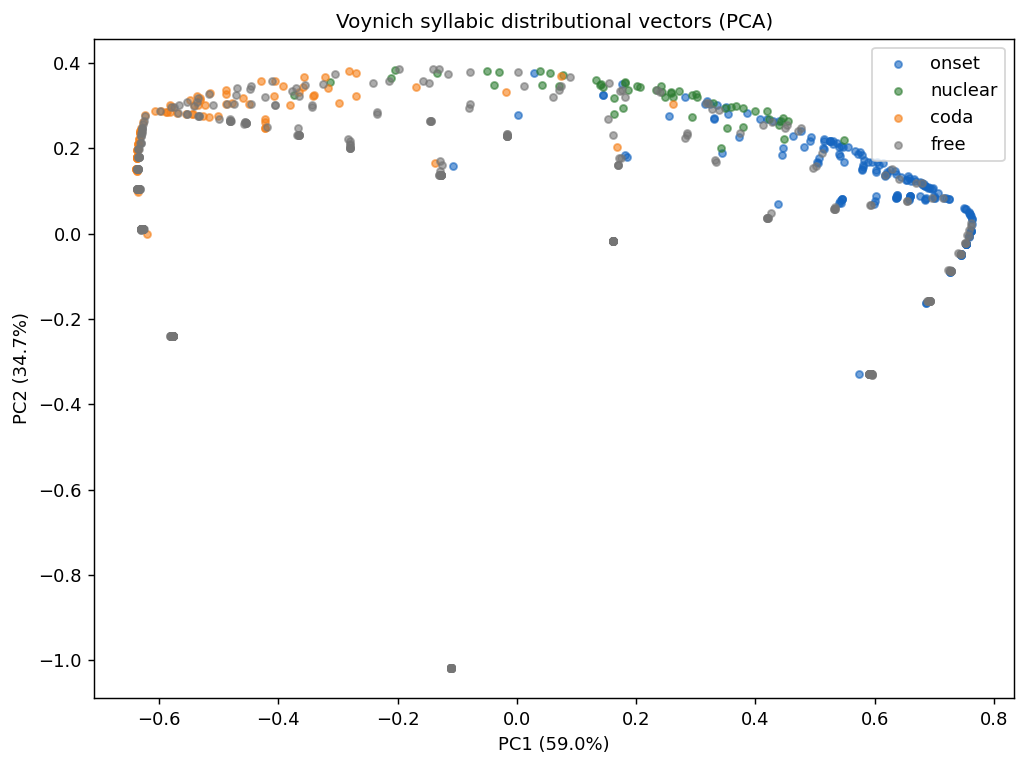

In [20]:
# ── Cell 13: Distributional vectors + PCA ────────────────────────

# Voynich vectors
vecs_v = compute_distributional_vectors(WORDS_SYL_V, clase_silaba_v)
print(f'Voynich: {len(vecs_v)} distributional vectors')

# Target vectors
VECS_TARGET = {}
for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]
    vecs = compute_distributional_vectors(ld['words_syl'], ld['clase'])
    VECS_TARGET[nombre] = vecs
    print(f'{nombre}: {len(vecs)} distributional vectors')

# PCA visualization (Voynich only, colored by class)
syls_with_vecs = [s for s in vecs_v if s in clase_silaba_v]
if len(syls_with_vecs) > 10:
    mat = np.array([vecs_v[s] for s in syls_with_vecs])
    mat_norm = mat / (np.linalg.norm(mat, axis=1, keepdims=True) + 1e-10)
    pca = PCA(n_components=2)
    coords = pca.fit_transform(mat_norm)

    fig, ax = plt.subplots(figsize=(8, 6))
    for clase, color in CLASE_COLORS.items():
        idx = [i for i, s in enumerate(syls_with_vecs) if clase_silaba_v.get(s) == clase]
        if idx:
            ax.scatter(coords[idx, 0], coords[idx, 1], c=color, s=15,
                      alpha=0.6, label=clase)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.set_title('Voynich syllabic distributional vectors (PCA)')
    ax.legend()
    plt.tight_layout()
    plt.show()

Turkish: score=-41.3354 (LM=-20.2658, para=0.0595, harm=-0.8931), mapped=792 syls
Finnish: score=-39.8892 (LM=-19.5617, para=0.0890, harm=-0.8994), mapped=792 syls
Hebreo: score=-37.5741 (LM=-18.3776, para=-0.0466, harm=-0.7489), mapped=767 syls
Árabe: score=-38.5386 (LM=-18.8258, para=-0.0033, harm=-0.8820), mapped=791 syls
Latin: score=-40.5311 (LM=-20.0516, para=0.2263, harm=-0.7675), mapped=595 syls
Arameo: score=-37.6320 (LM=-18.6293, para=0.2919, harm=-0.8112), mapped=792 syls

=== Ranking initialisation ===
  1. Hebreo: -37.5741
  2. Arameo: -37.6320
  3. Árabe: -38.5386
  4. Finnish: -39.8892
  5. Latin: -40.5311
  6. Turkish: -41.3354


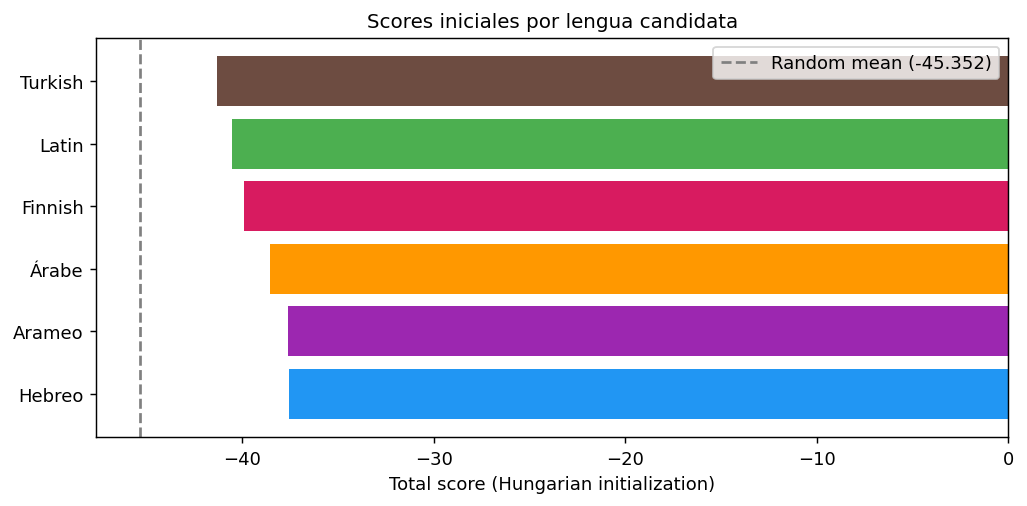

Guardado: aux_docs/bayesiano_initialisation.png


In [21]:
# ── Cell 14: Hungarian initialization per language ──────────────────────

INIT_STATES = {}
INIT_SCORES = {}

for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]
    vecs_t = VECS_TARGET[nombre]

    # Hungarian matching
    mapping = initialize_mapping_hungarian(vecs_v, vecs_t, clase_silaba_v, ld['clase'])
    state = MappingState(VOCAB_SYL_V, list(ld['clase'].keys()),
                          clase_silaba_v, ld['clase'])
    state.set_mapping(mapping)

    sc, comp = score_total(state, WORDS_SYL_V, ld['lm'],
                            paradigmas_v, pairs_nuc_cod_v,
                            ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    INIT_STATES[nombre] = state
    INIT_SCORES[nombre] = {'total': sc, **comp}
    print(f'{nombre}: score={sc:.4f} (LM={comp["lm"]:.4f}, '
          f'para={comp["paradigm"]:.4f}, harm={comp["harmony"]:.4f}), '
          f'mapped={len(mapping)} syls')

# Ranking
ranking = sorted(INIT_SCORES.items(), key=lambda x: x[1]['total'], reverse=True)
print('\n=== Ranking initialisation ===')
for i, (nombre, sc) in enumerate(ranking):
    print(f'  {i+1}. {nombre}: {sc["total"]:.4f}')

# Visualisation
fig, ax = plt.subplots(figsize=(8, 4))
nombres = [r[0] for r in ranking]
scores = [r[1]['total'] for r in ranking]
colors = [LANG_COLORS.get(n, '#999') for n in nombres]
ax.barh(nombres, scores, color=colors)
ax.set_xlabel('Total score (Hungarian initialization)')
ax.set_title('Initial scores by candidate language')
if random_scores:
    ax.axvline(np.mean(random_scores), color='gray', linestyle='--',
               label=f'Random mean ({np.mean(random_scores):.3f})')
    ax.legend()
plt.tight_layout()
plt.savefig('images/bayesiano_inicializacion.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: images/bayesiano_inicializacion.png')

## Adapted EM

**E-step**: Given the current mapping, the Voynich corpus is "translated" and evaluated under the target LM.

**M-step**: For each positional class, pairwise syllable swaps are tested. The swap that most improves the total score is accepted.

**Convergence**: Stops when the score does not improve for 5 consecutive iterations.

In [22]:
# ── Cell 16: Run EM for each language ────────────────────────────

EM_STATES = {}
EM_HISTORIES = {}

for nombre in LANG_DATA:
    print(f'\n=== EM: {nombre} ===')
    ld = LANG_DATA[nombre]
    init_state = INIT_STATES[nombre]

    em_state, em_history = em_syllable_decipher(
        WORDS_SYL_V, ld['lm'], paradigmas_v, pairs_nuc_cod_v,
        init_state, ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'],
        n_iter=30, patience=5)

    EM_STATES[nombre] = em_state
    EM_HISTORIES[nombre] = em_history

    improvement = em_history[-1] - em_history[0]
    print(f'  Iterations: {len(em_history)-1}')
    print(f'  Score: {em_history[0]:.4f} -> {em_history[-1]:.4f} (delta={improvement:+.4f})')


=== EM: Turkish ===
    iter 1: score=-41.5310 *
    iter 2: score=-41.2785 *
    iter 3: score=-41.1089 *
    iter 4: score=-40.9759 *
    iter 5: score=-40.8063 *
    iter 6: score=-40.7021 *
    iter 7: score=-40.5977 *
    iter 8: score=-40.3735 *
    iter 9: score=-40.3008 *
    iter 10: score=-40.1918 *
    iter 11: score=-40.0789 *
    iter 12: score=-40.0479 *
    iter 13: score=-39.9256 *
    iter 14: score=-39.8564 *
    iter 15: score=-39.7669 *
    iter 16: score=-39.7468 *
    iter 17: score=-39.7398 *
    iter 18: score=-39.6247 *
    iter 19: score=-39.4927 *
    iter 20: score=-39.4347 *
    iter 21: score=-39.3770 *
    iter 22: score=-39.3734 *
    iter 23: score=-39.3230 *
    iter 24: score=-39.3138 *
    iter 25: score=-39.2921 *
    iter 26: score=-39.2732 *
    iter 27: score=-39.2478 *
    iter 28: score=-39.2069 *
    iter 29: score=-39.1821 *
    iter 30: score=-39.1459 *
  Iterations: 30
  Score: -41.5958 -> -39.1459 (delta=+2.4499)

=== EM: Finnish ===
    

=== Ranking post-EM ===
  1. Arameo: -36.4801 (init=-37.6320, delta=+1.1519)
  2. Hebreo: -36.6627 (init=-37.5741, delta=+0.9113)
  3. Árabe: -37.4064 (init=-38.5386, delta=+1.1322)
  4. Finnish: -39.2772 (init=-39.8892, delta=+0.6121)
  5. Latin: -39.6597 (init=-40.5311, delta=+0.8714)
  6. Turkish: -39.8903 (init=-41.3354, delta=+1.4451)


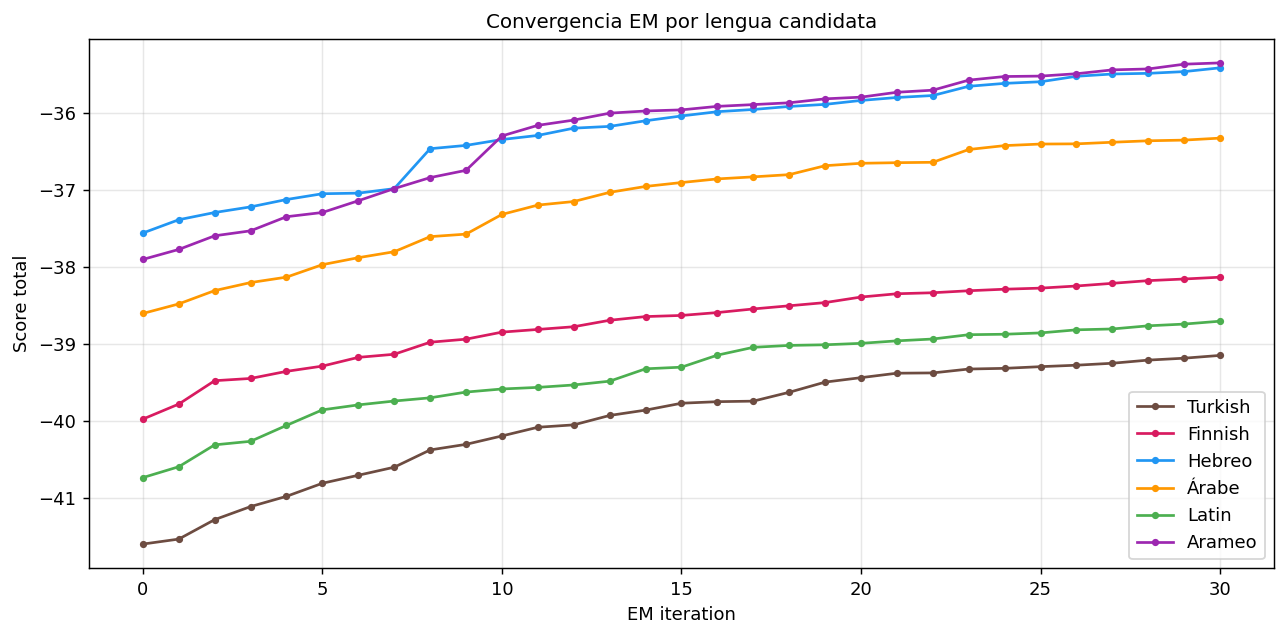

Guardado: aux_docs/bayesiano_em_convergence.png


In [23]:
# ── Cell 17: EM results ───────────────────────────────────────────

# Ranking post-EM
em_scores = {}
for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]
    sc, comp = score_total(EM_STATES[nombre], WORDS_SYL_V, ld['lm'],
                            paradigmas_v, pairs_nuc_cod_v,
                            ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    em_scores[nombre] = {'total': sc, **comp}

ranking_em = sorted(em_scores.items(), key=lambda x: x[1]['total'], reverse=True)
print('=== Ranking post-EM ===')
for i, (nombre, sc) in enumerate(ranking_em):
    init_sc = INIT_SCORES[nombre]['total']
    print(f'  {i+1}. {nombre}: {sc["total"]:.4f} (init={init_sc:.4f}, '
          f'delta={sc["total"]-init_sc:+.4f})')

# Convergence curves
fig, ax = plt.subplots(figsize=(10, 5))
for nombre in LANG_DATA:
    hist = EM_HISTORIES[nombre]
    ax.plot(range(len(hist)), hist, 'o-', label=nombre,
            color=LANG_COLORS.get(nombre, '#999'), markersize=3)
ax.set_xlabel('EM iteration')
ax.set_ylabel('Score total')
ax.set_title('EM convergence by candidate language')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/bayesiano_em_convergencia.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: images/bayesiano_em_convergencia.png')

## MCMC with simulated annealing

**Proposal**: Swap 2 Voynich syllables of the same positional class.

**Acceptance**: Metropolis-Hastings: $\alpha = \min(1, e^{(S_{new} - S_{old})/T})$

**Annealing**: Temperature decreases geometrically from $T_{start}=1.0$ to $T_{end}=0.01$.

Executed on the top-2 languages from the EM ranking, starting from the best EM mapping.

In [24]:
# ── Cell 19: MCMC multi-chain for top-2 languages ─────────────────────
# Adaptive annealing: T_start automatically calibrated from observed deltas
# 15000 iter × 4 chains × 2 languages ≈ 60 min

top2_langs = [r[0] for r in ranking_em[:2]]
print(f'MCMC multi-chain on: {top2_langs}')
print(f'Configuration: 4 chains, 15000 iter, burn_in=3000, thin=5, adaptive=True')

MCMC_RESULTS = {}

for nombre in top2_langs:
    print(f'\n=== MCMC multi-chain: {nombre} ===')
    ld = LANG_DATA[nombre]
    em_state = EM_STATES[nombre]

    result = mcmc_multi_chain(
        em_state, WORDS_SYL_V, ld['lm'], paradigmas_v, pairs_nuc_cod_v,
        ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'],
        n_chains=4, seeds=(42, 137, 256, 999),
        n_iter=15000, corpus_sample_size=2000, burn_in=3000, thin=5,
        adaptive=True, target_accept=0.50,
        calibration_samples=300, T_ratio=100)

    MCMC_RESULTS[nombre] = result

    sc_em = em_scores[nombre]['total']
    sc_mcmc, _ = score_total(result['best_state'], WORDS_SYL_V, ld['lm'],
                              paradigmas_v, pairs_nuc_cod_v,
                              ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    mean_accept = np.mean([ch['accept_rate'] for ch in result['chains']])
    print(f'  Mean accept rate: {mean_accept:.1%}')
    print(f'  Score: EM={sc_em:.4f} -> MCMC={sc_mcmc:.4f} (delta={sc_mcmc-sc_em:+.4f})')
    print(f'  Best score across chains: {result["best_score"]:.4f}')

MCMC multi-chain sobre: ['Arameo', 'Hebreo']
Configuration: 4 chains, 15000 iter, burn_in=3000, thin=5, adaptive=True

=== MCMC multi-chain: Arameo ===
  Chain 1/4 (seed=42)
    Adaptive T: median|delta|=0.0091, p25=0.0021 -> T_start=0.013144, T_end=0.00013144
    MCMC iter 1000: score=-36.2128, best=-36.0259, T=0.009672, accept=59.1%
    MCMC iter 2000: score=-36.1315, best=-36.0259, T=0.007115, accept=58.5%
    MCMC iter 3000: score=-35.9956, best=-35.9491, T=0.005234, accept=56.6%
    MCMC iter 4000: score=-35.7195, best=-35.7195, T=0.003850, accept=54.2%
    MCMC iter 5000: score=-35.5662, best=-35.5658, T=0.002832, accept=51.4%
    MCMC iter 6000: score=-35.3471, best=-35.3450, T=0.002084, accept=49.3%
    MCMC iter 7000: score=-35.0113, best=-35.0104, T=0.001533, accept=46.8%
    MCMC iter 8000: score=-34.7550, best=-34.7550, T=0.001128, accept=44.7%
    MCMC iter 9000: score=-34.5193, best=-34.5183, T=0.000829, accept=42.9%
    MCMC iter 10000: score=-34.3599, best=-34.3596, T=0

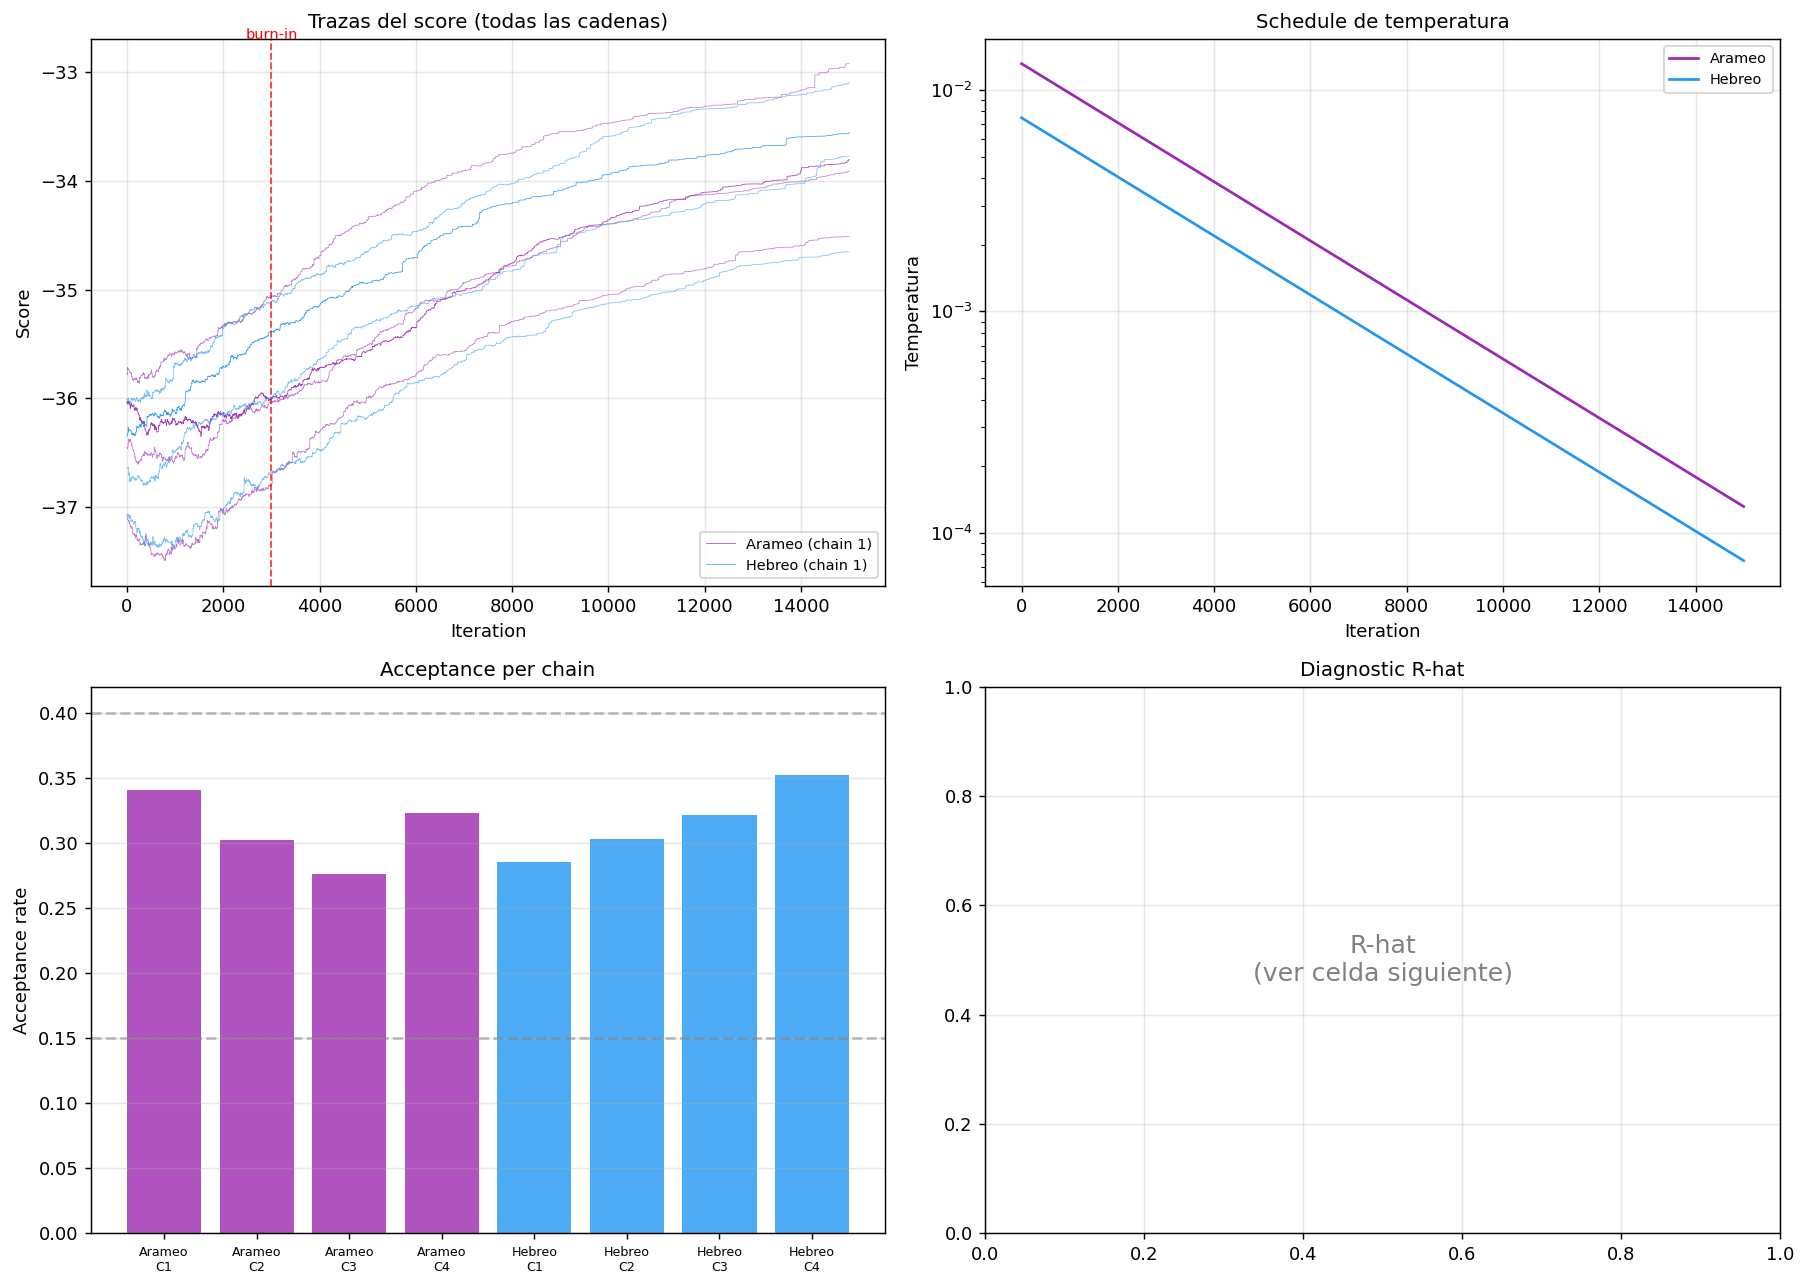

Guardado: aux_docs/bayesiano_mcmc_diagnostics.png


In [25]:
# ── Cell 20: Diagnostics MCMC multi-chain ───────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for nombre in MCMC_RESULTS:
    res = MCMC_RESULTS[nombre]
    color = LANG_COLORS.get(nombre, '#999')
    chains = res['chains']
    burn_in = res.get('burn_in', 3000)

    # (0,0) Score traces: all chains overlaid with burn-in marker
    for ci, ch in enumerate(chains):
        alpha = 0.6 if ci > 0 else 0.9
        lbl = f'{nombre} (chain {ci+1})' if ci == 0 else f'_chain {ci+1}'
        axes[0, 0].plot(ch['chain_scores'], alpha=alpha, color=color,
                        lw=0.4, label=lbl if ci == 0 else None)
    axes[0, 0].axvline(burn_in, color='red', ls='--', alpha=0.5, lw=1)

axes[0, 0].set_xlabel('Iteration')
axes[0, 0].set_ylabel('Score')
axes[0, 0].set_title('Score traces (all chains)')
axes[0, 0].legend(fontsize=8)
axes[0, 0].annotate('burn-in', xy=(burn_in, axes[0, 0].get_ylim()[1]),
                     fontsize=8, color='red', ha='center')
axes[0, 0].grid(True, alpha=0.3)

# (0,1) Temperature schedule (same for all chains)
for nombre in MCMC_RESULTS:
    res = MCMC_RESULTS[nombre]
    color = LANG_COLORS.get(nombre, '#999')
    if res['chains']:
        axes[0, 1].plot(res['chains'][0]['temperatures'], color=color, label=nombre)
axes[0, 1].set_xlabel('Iteration')
axes[0, 1].set_ylabel('Temperature')
axes[0, 1].set_title('Temperature schedule')
axes[0, 1].set_yscale('log')
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, alpha=0.3)

# (1,0) Per-chain acceptance rate bars
bar_data = []
bar_labels = []
bar_colors = []
for nombre in MCMC_RESULTS:
    res = MCMC_RESULTS[nombre]
    color = LANG_COLORS.get(nombre, '#999')
    for ci, ch in enumerate(res['chains']):
        bar_data.append(ch['accept_rate'])
        bar_labels.append(f'{nombre}\nC{ci+1}')
        bar_colors.append(color)

axes[1, 0].bar(range(len(bar_data)), bar_data, color=bar_colors, alpha=0.8)
axes[1, 0].set_xticks(range(len(bar_data)))
axes[1, 0].set_xticklabels(bar_labels, fontsize=7)
axes[1, 0].set_ylabel('Acceptance rate')
axes[1, 0].set_title('Acceptance per chain')
axes[1, 0].axhline(0.15, color='gray', ls='--', alpha=0.5)
axes[1, 0].axhline(0.40, color='gray', ls='--', alpha=0.5)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# (1,1) Reserved for R-hat (populated after Cell 22)
axes[1, 1].text(0.5, 0.5, 'R-hat\n(see next cell)', transform=axes[1, 1].transAxes,
                ha='center', va='center', fontsize=14, color='gray')
axes[1, 1].set_title('Diagnostic R-hat')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/bayesiano_mcmc_diagnosticos.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: images/bayesiano_mcmc_diagnosticos.png')

In [26]:
# ── Cell 21: Distribution posterior multi-chain + R-hat ──────────────

RHAT_DATA = {}

for nombre in MCMC_RESULTS:
    res = MCMC_RESULTS[nombre]
    burn_in = res.get('burn_in', 3000)

    posterior, rhat, n_samples = posterior_multi_chain(res, burn_in=burn_in)

    MCMC_RESULTS[nombre]['posterior'] = posterior
    MCMC_RESULTS[nombre]['rhat'] = rhat
    RHAT_DATA[nombre] = rhat

    n_total = len(posterior)
    n_gt50 = sum(1 for sv in posterior if max(posterior[sv].values()) > 0.5)
    n_gt70 = sum(1 for sv in posterior if max(posterior[sv].values()) > 0.7)
    n_gt90 = sum(1 for sv in posterior if max(posterior[sv].values()) > 0.9)
    mean_conf = np.mean([max(p.values()) for p in posterior.values()]) if posterior else 0

    # R-hat stats
    rhat_vals = [v for v in rhat.values() if not np.isnan(v) and v < float('inf')]
    n_converged = sum(1 for v in rhat_vals if v < 1.1)
    median_rhat = np.median(rhat_vals) if rhat_vals else float('nan')

    print(f'\n=== Posterior multi-chain: {nombre} ===')
    print(f'  Total effective samples: {n_samples:,}')
    print(f'  Mapped syllables: {n_total}')
    print(f'  Confidence > 50%: {n_gt50} ({n_gt50/max(n_total,1):.0%})')
    print(f'  Confidence > 70%: {n_gt70} ({n_gt70/max(n_total,1):.0%})')
    print(f'  Confidence > 90%: {n_gt90} ({n_gt90/max(n_total,1):.0%})')
    print(f'  Mean confidence: {mean_conf:.3f}')
    print(f'  --- R-hat ---')
    print(f'  Median R-hat:    {median_rhat:.4f}')
    print(f'  Converged (R-hat < 1.1): {n_converged}/{len(rhat_vals)} '
          f'({n_converged/max(len(rhat_vals),1):.0%})')


=== Posterior multi-chain: Arameo ===
  Muestras efectivas totales: 9,604
  Mapped syllables: 792
  Confianza > 50%: 36 (5%)
  Confianza > 70%: 23 (3%)
  Confianza > 90%: 11 (1%)
  Confianza media: 0.207
  --- R-hat ---
  R-hat mediana:   1.5377
  Convergidos (R-hat < 1.1): 42/705 (6%)

=== Posterior multi-chain: Hebreo ===
  Muestras efectivas totales: 9,604
  Mapped syllables: 767
  Confianza > 50%: 38 (5%)
  Confianza > 70%: 25 (3%)
  Confianza > 90%: 14 (2%)
  Confianza media: 0.208
  --- R-hat ---
  R-hat mediana:   1.4849
  Convergidos (R-hat < 1.1): 41/674 (6%)


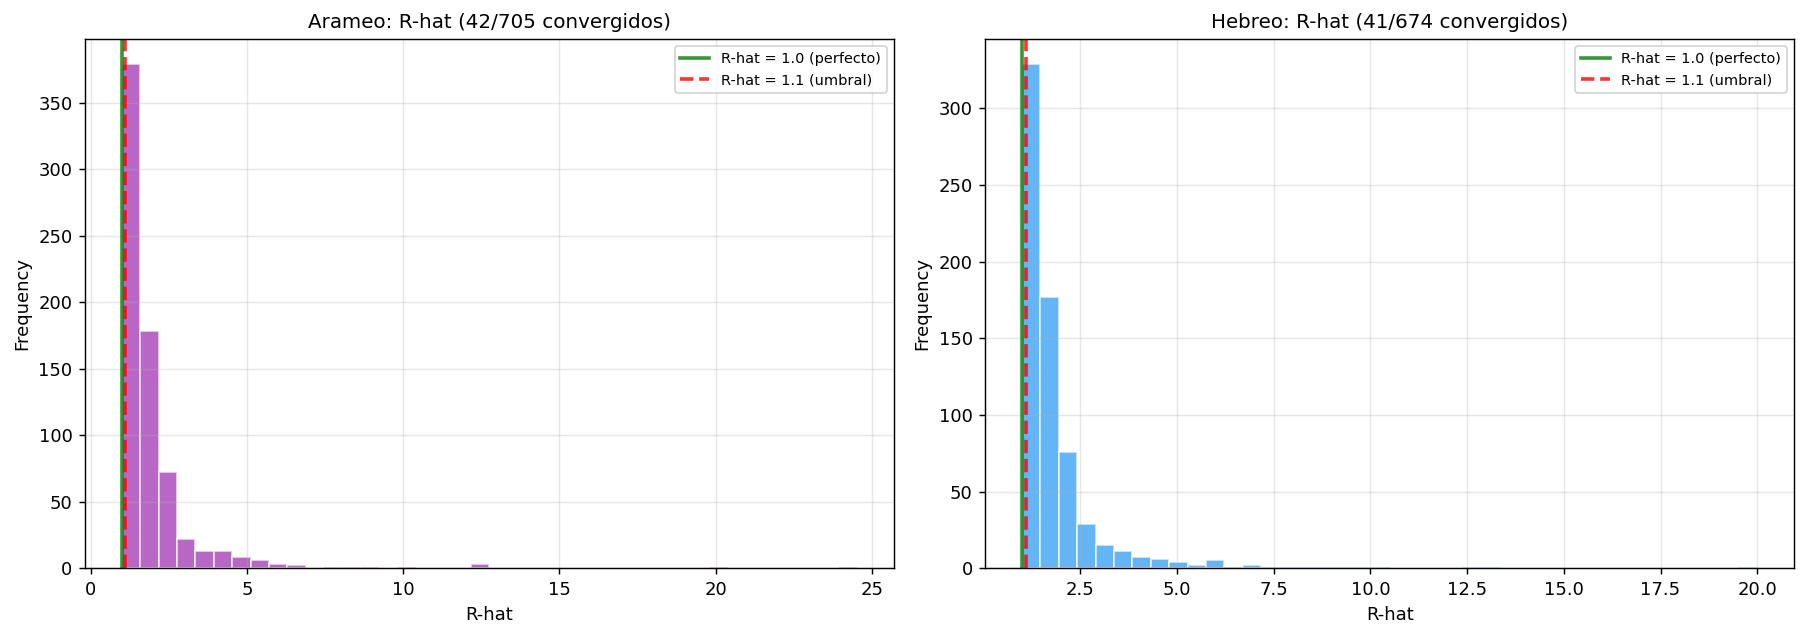

Guardado: aux_docs/bayesiano_rhat_diagnostics.png


In [27]:
# ── Cell 21b: R-hat histogram ───────────────────────────────────────

n_langs = len(RHAT_DATA)
fig, axes = plt.subplots(1, n_langs, figsize=(7 * n_langs, 5), squeeze=False)

for i, nombre in enumerate(RHAT_DATA):
    ax = axes[0, i]
    rhat = RHAT_DATA[nombre]
    rhat_vals = [v for v in rhat.values() if not np.isnan(v) and v < float('inf')]

    if rhat_vals:
        ax.hist(rhat_vals, bins=40, color=LANG_COLORS.get(nombre, '#999'),
                alpha=0.7, edgecolor='white')
        ax.axvline(1.0, color='green', ls='-', lw=2, alpha=0.8, label='R-hat = 1.0 (perfect)')
        ax.axvline(1.1, color='red', ls='--', lw=2, alpha=0.8, label='R-hat = 1.1 (threshold)')

        n_conv = sum(1 for v in rhat_vals if v < 1.1)
        ax.set_title(f'{nombre}: R-hat ({n_conv}/{len(rhat_vals)} converged)')
    else:
        ax.set_title(f'{nombre}: no R-hat data')

    ax.set_xlabel('R-hat')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('images/bayesiano_rhat_diagnosticos.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: images/bayesiano_rhat_diagnosticos.png')

## Evaluation and reconstruction

Final ranking of candidate languages with detailed metrics. Paradigm reconstruction under the best mapping. Mapping confidence analysis.

In [28]:
# ── Cell 23: Ranking final ───────────────────────────────────────────

rows = []
for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]

    # Use MCMC result if available, else EM
    if nombre in MCMC_RESULTS:
        state = MCMC_RESULTS[nombre]['best_state']
        phase = 'MCMC'
    else:
        state = EM_STATES[nombre]
        phase = 'EM'

    ev = evaluate_candidate(state, WORDS_SYL_V, ld['lm'], paradigmas_v, pairs_nuc_cod_v,
                            ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    rows.append({
        'Language': nombre,
        'Phase': phase,
        'Score total': ev["score_total"],
        'S_LM': ev["score_lm"],
        'S_paradigm': ev["score_paradigm"],
        'S_harmony': ev["score_harmony"],
        'Mapped PPX': ev["perplexity_mapped"],
        'Native PPX': ld["ppx_native"],
        'Ratio PPX': ev["perplexity_mapped"]/ld["ppx_native"],
    })

df_ranking = pd.DataFrame(rows)
df_ranking = df_ranking.sort_values('Score total', ascending=False)

# Format for display
fmt = df_ranking.copy()
for col in ['Score total','S_LM','S_paradigm','S_harmony']:
    fmt[col] = fmt[col].map(lambda x: f'{x:.4f}')
fmt['Mapped PPX'] = fmt['Mapped PPX'].map(lambda x: f'{x:.1f}')
fmt['Native PPX'] = fmt['Native PPX'].map(lambda x: f'{x:.1f}')
fmt['Ratio PPX'] = fmt['Ratio PPX'].map(lambda x: f'{x:.2f}')
print(fmt.to_string(index=False))

 Lengua Fase Score total     S_LM S_paradigma S_harmony PPX mapeada PPX nativa Ratio PPX
 Hebreo MCMC    -35.7009 -17.5522      0.0486   -0.6694       100.2       25.1      3.99
 Arameo MCMC    -35.7077 -17.7812      0.3633   -0.6902       106.4       25.3      4.21
  Árabe   EM    -37.4064 -18.3907      0.1396   -0.8343       124.9       25.4      4.91
Finnish   EM    -39.2772 -19.3367      0.1843   -0.8802       160.0       29.5      5.43
  Latin   EM    -39.6597 -19.7156      0.2978   -0.6752       176.8       13.7     12.88
Turkish   EM    -39.8903 -19.6898      0.2500   -0.8857       175.6       33.2      5.29


Mejor language: Hebreo



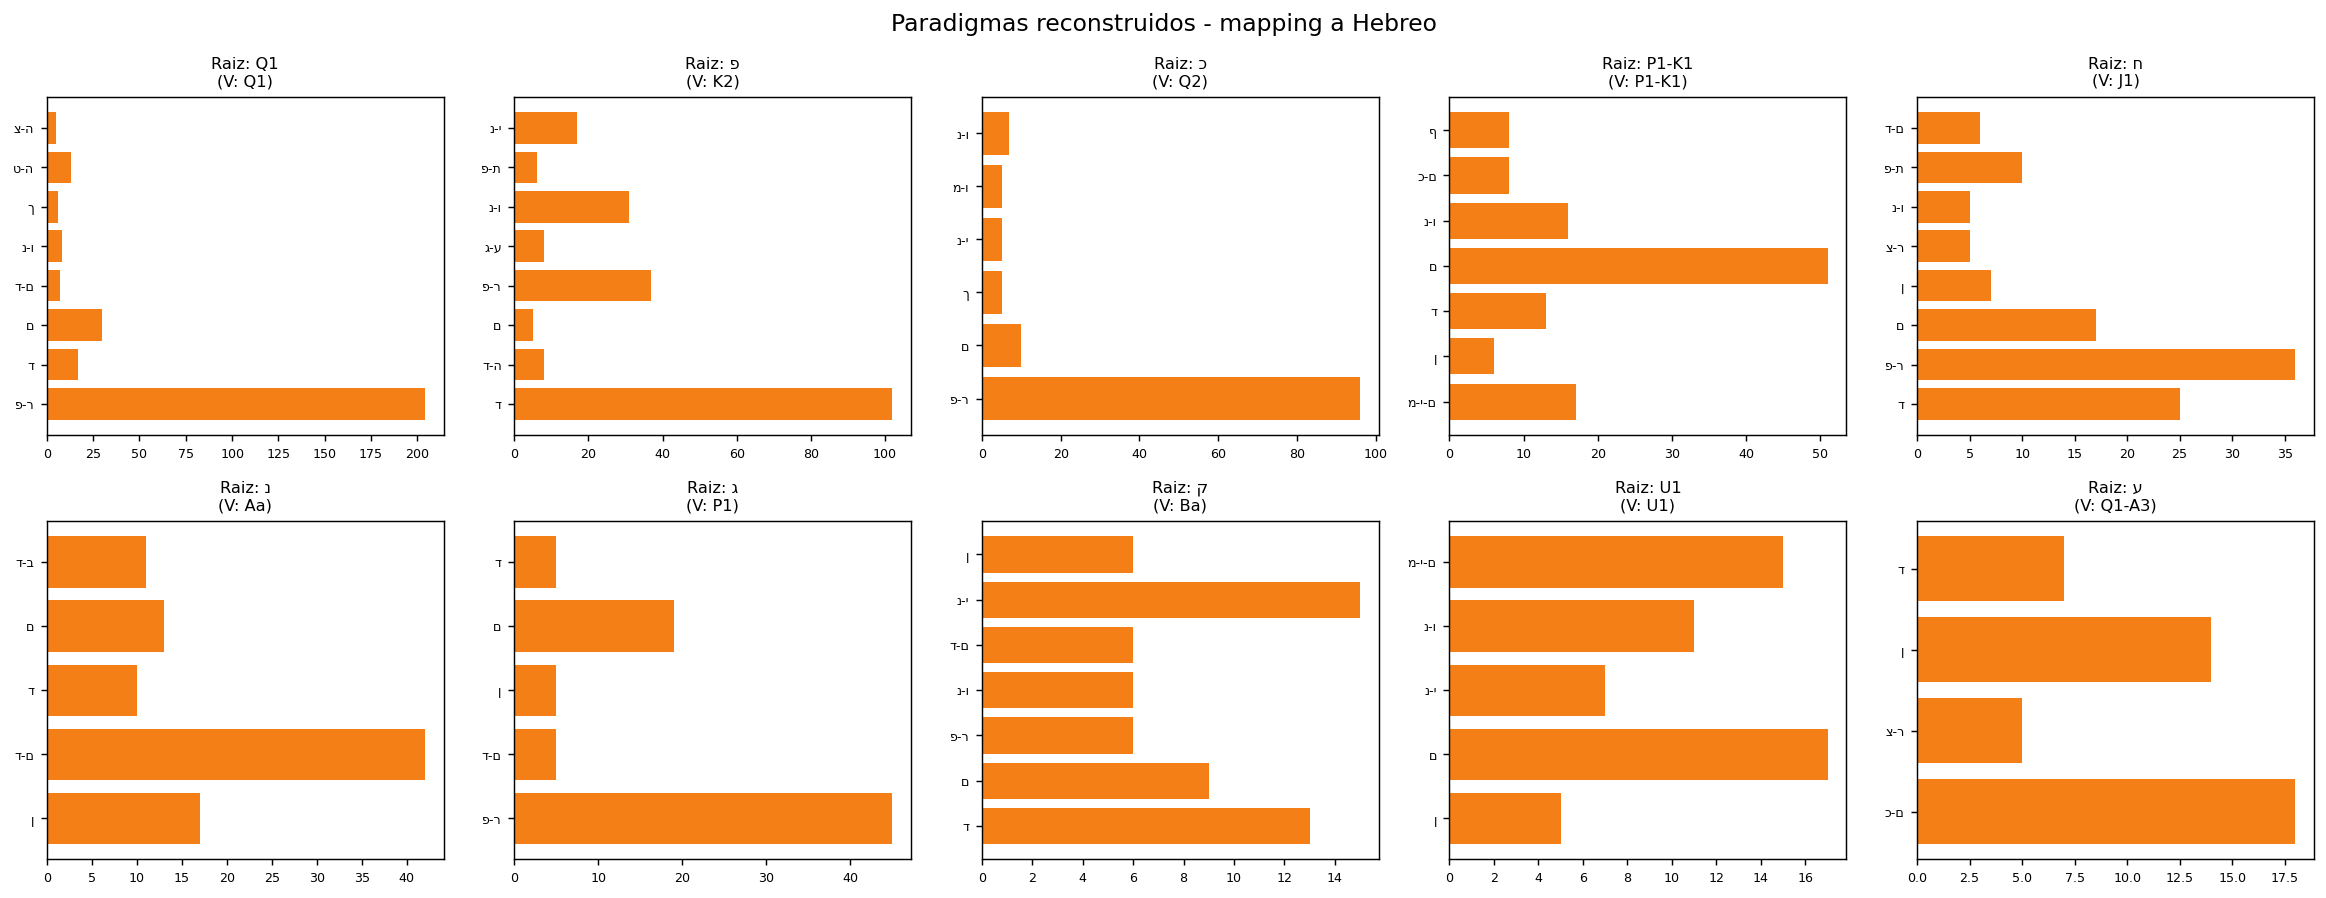

Guardado: aux_docs/bayesiano_paradigmas_mapeados.png


In [30]:
# ── Cell 24: Reconstructed paradigms ────────────────────────────────

# Use best language
best_lang = df_ranking.iloc[0]['Language']
print(f'Best language: {best_lang}')
print()

if best_lang in MCMC_RESULTS:
    best_state = MCMC_RESULTS[best_lang]['best_state']
else:
    best_state = EM_STATES[best_lang]

paradigms_recon = reconstruct_paradigms(best_state, paradigmas_v, top_n=10)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

for idx, (raiz, info) in enumerate(paradigms_recon.items()):
    if idx >= 10:
        break
    ax = axes[idx]
    sufs = info['suffixes']
    labels = [syl_to_str(s) for s in sufs.keys()]
    counts = list(sufs.values())

    if labels:
        colors_bar = [CLASE_COLORS.get('coda', '#999')] * len(labels)
        ax.barh(labels, counts, color=colors_bar)
    ax.set_title(f'Root: {syl_to_str(info["mapped_root"])}\n'
                 f'(V: {syl_to_str(raiz)})', fontsize=9)
    ax.tick_params(labelsize=7)

plt.suptitle(f'Reconstructed paradigms — mapping to {best_lang}', fontsize=13)
plt.tight_layout()
plt.savefig('images/bayesiano_paradigmas_mapeados.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: images/bayesiano_paradigmas_mapeados.png')

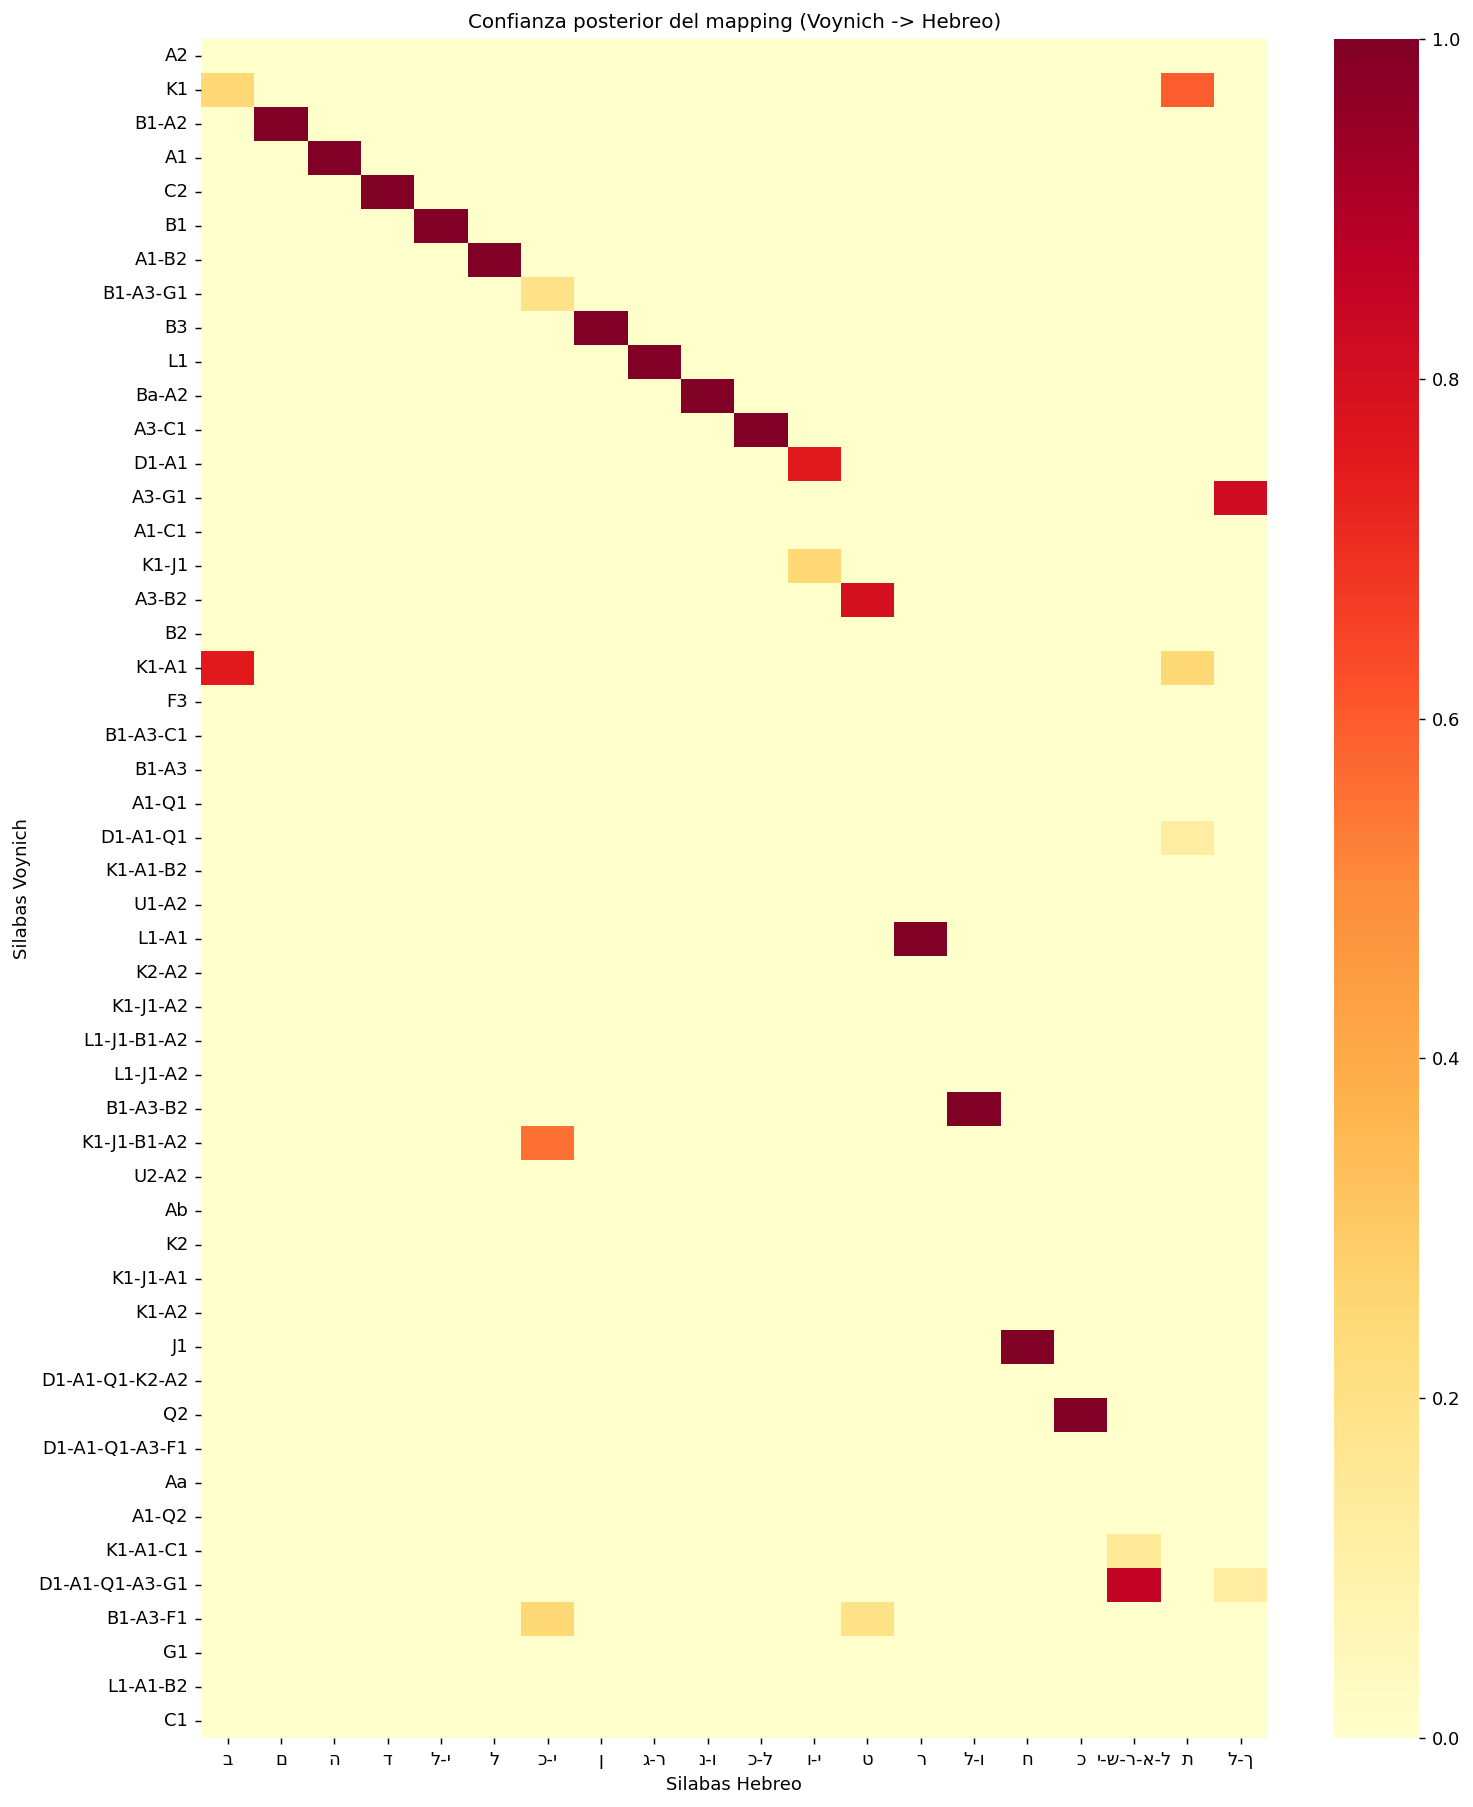

Guardado: aux_docs/bayesiano_confianza_mapping.png


In [31]:
# ── Cell 25: Confidence heatmap ────────────────────────────────────

if best_lang in MCMC_RESULTS:
    posterior = MCMC_RESULTS[best_lang]['posterior']

    # Top-50 Voynich syls by frequency that have posterior
    top_v_syls = sorted([s for s in posterior if s in syl_freq_v],
                        key=lambda s: syl_freq_v[s], reverse=True)[:50]

    # Build matrix
    all_targets = set()
    for sv in top_v_syls:
        all_targets.update(posterior[sv].keys())
    # Take top targets by total posterior mass
    target_mass = Counter()
    for sv in top_v_syls:
        for st, p in posterior[sv].items():
            target_mass[st] += p
    top_targets = [t for t, _ in target_mass.most_common(min(20, len(target_mass)))]

    if top_v_syls and top_targets:
        mat = np.zeros((len(top_v_syls), len(top_targets)))
        for i, sv in enumerate(top_v_syls):
            for j, st in enumerate(top_targets):
                mat[i, j] = posterior[sv].get(st, 0.0)

        fig, ax = plt.subplots(figsize=(12, 14))
        sns.heatmap(mat, ax=ax, cmap='YlOrRd', vmin=0, vmax=1,
                    xticklabels=[syl_to_str(t) for t in top_targets],
                    yticklabels=[syl_to_str(s) for s in top_v_syls])
        ax.set_xlabel(f'{best_lang} syllables')
        ax.set_ylabel('Voynich syllables')
        ax.set_title(f'Posterior mapping confidence (Voynich -> {best_lang})')
        plt.tight_layout()
        plt.savefig('images/bayesiano_confianza_mapping.png', dpi=180,
                    bbox_inches='tight')
        plt.show()
        print('Saved: images/bayesiano_confianza_mapping.png')
    else:
        print('Insufficient data for heatmap')
else:
    print(f'No MCMC result for {best_lang}')

In [32]:
# ── Cell 25b: Text reconstruction (qualitative Hebrew analysis) ──

if best_lang in MCMC_RESULTS:
    posterior = MCMC_RESULTS[best_lang]['posterior']
    best_state = MCMC_RESULTS[best_lang]['best_state']

    recon = reconstruct_text(best_state, posterior, WORDS_SYL_V,
                             n_words=50, confidence_threshold=0.7)

    print(f'=== Reconstruction of first 50 words ({best_lang}) ===')
    print(f'Confidence threshold: 70%\n')

    total_syls = 0
    confident_syls = 0

    for i, word_info in enumerate(recon):
        parts = []
        for s in word_info:
            total_syls += 1
            if s['confident']:
                confident_syls += 1
                parts.append(f'[{syl_to_str(s["mapped"])}]')
            else:
                parts.append(f'_{syl_to_str(s["voynich"])}_')
        word_str = '.'.join(parts)
        conf_vals = [f'{s["confidence"]:.0%}' for s in word_info]
        print(f'  {i+1:2d}. {word_str:40s}  conf: {", ".join(conf_vals)}')

    pct = confident_syls / max(total_syls, 1) * 100
    print(f'\n--- Summary ---')
    print(f'  Total syllables:    {total_syls}')
    print(f'  Mapped (>70%):      {confident_syls} ({pct:.1f}%)')
    print(f'  Uncertain:          {total_syls - confident_syls} ({100 - pct:.1f}%)')
else:
    print(f'No MCMC result for {best_lang}')

=== Reconstruction of first 50 words (Hebreo) ===
Umbral de confianza: 70%

   1. _P2-A3_._K1-A2_.[ד]                       conf: 0%, 57%, 100%
   2. _A2-Q1-A3-B2_                             conf: 15%
   3. [כ-ל]                                     conf: 100%
   4. _Aa_._Q2-A3-G1_                           conf: 50%, 25%
   5. _L1-A1-B2_                                conf: 25%
   6. _L1-A1-C1-A2_                             conf: 13%
   7. _U5-C2_.[ח].[ד]                           conf: 0%, 100%, 100%
   8. _A2_                                      conf: 50%
   9. _Q1_._A1-C1_                              conf: 0%, 25%
  10. _L1-A1-B2_.[ם]                            conf: 25%, 100%
  11. _C2-A1-C1-A2_                             conf: 0%
  12. _U1_.[כ-ל]                                conf: 0%, 100%
  13. _A1-C1-A2_                                conf: 18%
  14. _Q1-A3_.[כ-ם]                             conf: 25%, 73%
  15. _K1_._Q2-A3-G1_                           conf: 59%, 25%
  1

=== Coherencia del mapping (Hebreo) ===
  PPX mediana (words mapeadas): 70.3
  PPX nativa:                      969.9
  Overlap de bigramas:             8.9%
  Score de coherencia:             0.1262


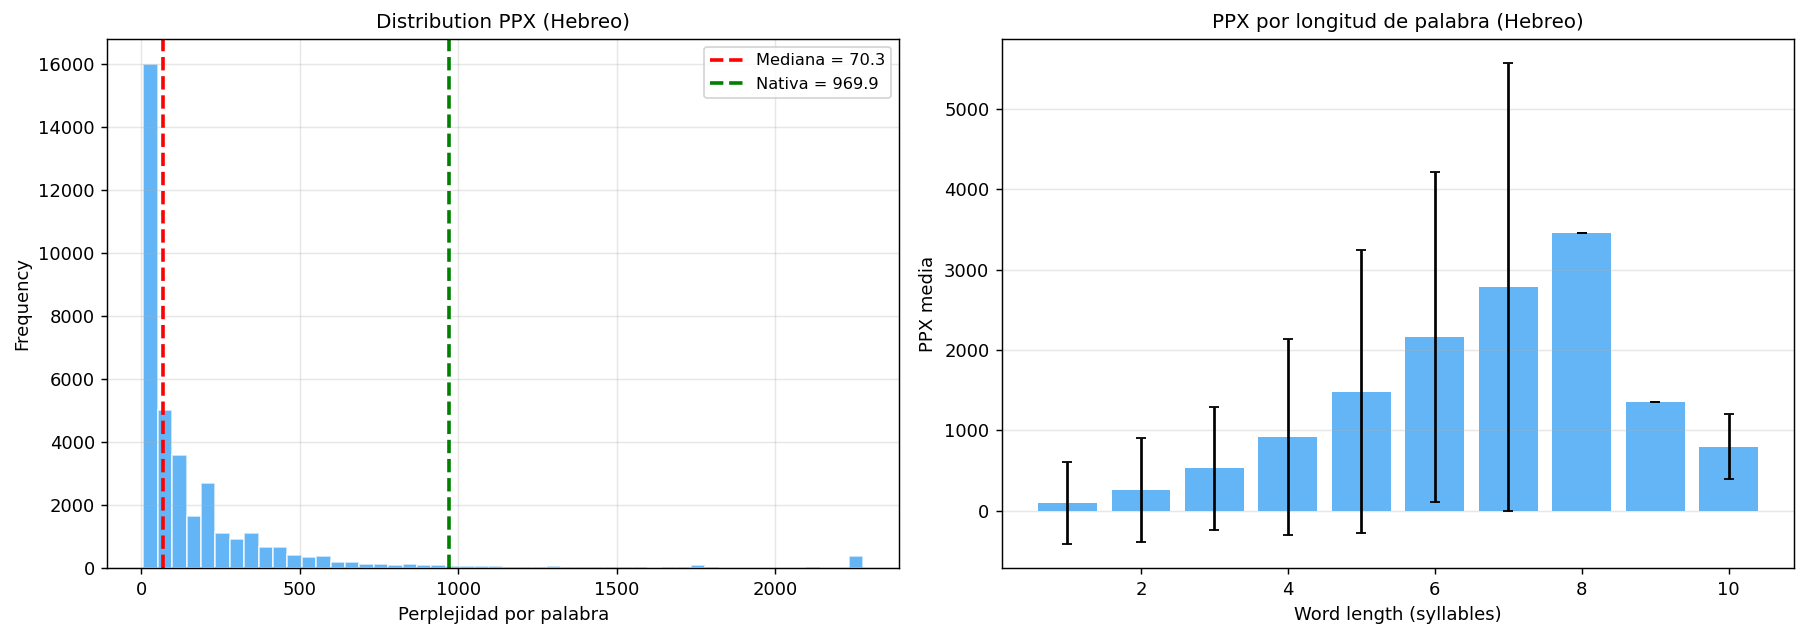

Guardado: aux_docs/bayesiano_coherencia_Hebrew.png


In [33]:
# ── Cell 25c: Coherence analysis ─────────────────────────────────

if best_lang in MCMC_RESULTS:
    posterior = MCMC_RESULTS[best_lang]['posterior']
    best_state = MCMC_RESULTS[best_lang]['best_state']
    ld = LANG_DATA[best_lang]

    coh = target_coherence_analysis(best_state, posterior, WORDS_SYL_V, ld['lm'],
                                    confidence_threshold=0.7)

    MCMC_RESULTS[best_lang]['coherence'] = coh

    print(f'=== Mapping coherence ({best_lang}) ===')
    print(f'  Median PPX (mapped words):    {coh["median_ppx"]:.1f}')
    print(f'  Native PPX:                      {coh["native_ppx"]:.1f}')
    print(f'  Bigram overlap:                  {coh["bigram_overlap"]:.1%}')
    print(f'  Coherence score:                 {coh["coherence_score"]:.4f}')

    # Plot: PPX distribution + PPX by word length
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # (0) PPX distribution histogram
    ppx_vals = [w['ppx'] for w in coh['word_ppx'] if w['ppx'] < float('inf')]
    ppx_clipped = [min(p, np.percentile(ppx_vals, 99)) for p in ppx_vals]
    axes[0].hist(ppx_clipped, bins=50, color=LANG_COLORS.get(best_lang, '#2196F3'),
                 alpha=0.7, edgecolor='white')
    axes[0].axvline(coh['median_ppx'], color='red', ls='--', lw=2,
                    label=f'Median = {coh["median_ppx"]:.1f}')
    axes[0].axvline(coh['native_ppx'], color='green', ls='--', lw=2,
                    label=f'Native = {coh["native_ppx"]:.1f}')
    axes[0].set_xlabel('Per-word perplexity')
    axes[0].set_ylabel('Frequency')
    axes[0].set_title(f'PPX distribution ({best_lang})')
    axes[0].legend(fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # (1) PPX by word length
    from collections import defaultdict as _dd
    ppx_by_len = _dd(list)
    for w in coh['word_ppx']:
        if w['ppx'] < float('inf'):
            ppx_by_len[w['word_len']].append(w['ppx'])

    lengths = sorted(ppx_by_len.keys())
    means = [np.mean(ppx_by_len[l]) for l in lengths]
    stds = [np.std(ppx_by_len[l]) for l in lengths]

    axes[1].bar(lengths, means, yerr=stds, color=LANG_COLORS.get(best_lang, '#2196F3'),
                alpha=0.7, capsize=3)
    axes[1].set_xlabel('Word length (syllables)')
    axes[1].set_ylabel('Mean PPX')
    axes[1].set_title(f'PPX by word length ({best_lang})')
    axes[1].grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.savefig('images/bayesiano_coherencia_hebreo.png', dpi=180, bbox_inches='tight')
    plt.show()
    print('Saved: images/bayesiano_coherencia_hebreo.png')
else:
    print(f'No MCMC result for {best_lang}')

=== Top-30 mappings more confiables (Hebreo) ===
   voynich_syl target_syl  confidence positional_class  frequency
            C2          ד      1.0000             coda       1556
         B1-A2          ם      1.0000             coda       1933
            A1          ה      1.0000            onset       1885
            L1        ג-ר      1.0000             free        892
            Q2          כ      1.0000          nuclear        294
            J1          ח      1.0000          nuclear        311
         A3-C1        כ-ל      1.0000             free        822
         L1-A1          ר      1.0000             free        428
            B1        ל-י      1.0000             free       1528
            B3          ן      1.0000             coda        957
         Ba-A2        נ-ו      1.0000             coda        852
      B1-A3-B2        ל-ו      1.0000             free        388
         A1-B2          ל      1.0000             free       1269
            B2        ק-ר  

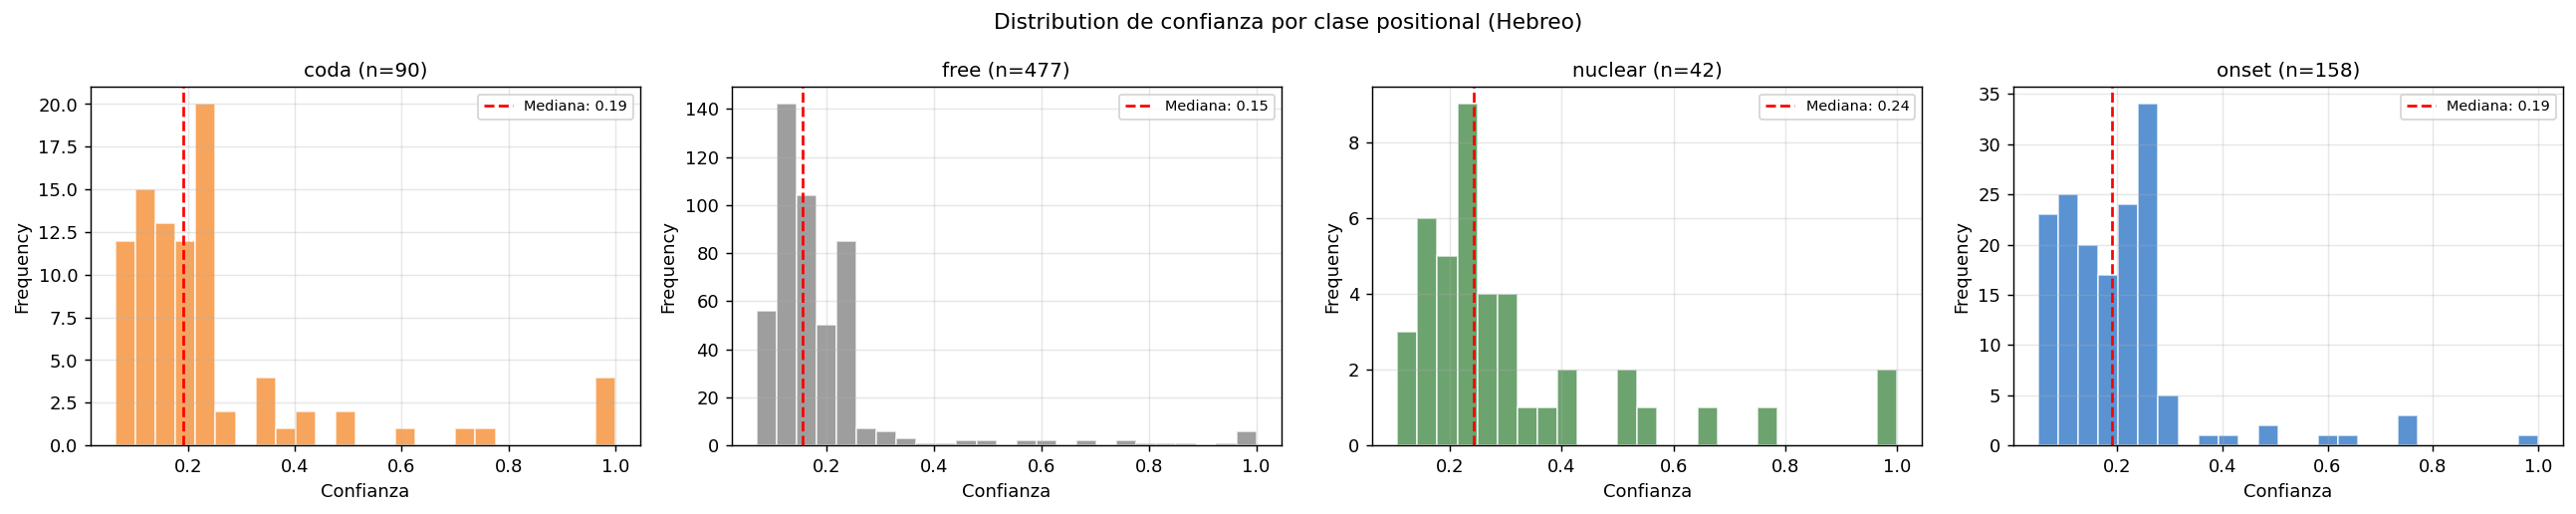

Guardado: aux_docs/bayesiano_confianza_por_clase.png


In [34]:
# ── Cell 25d: Mapping table + confidence by class ─────────────────

if best_lang in MCMC_RESULTS:
    posterior = MCMC_RESULTS[best_lang]['posterior']
    best_state = MCMC_RESULTS[best_lang]['best_state']

    df_map = build_mapping_table(best_state, posterior, clase_silaba_v, syl_freq_v)

    print(f'=== Top-30 most confident mappings ({best_lang}) ===')
    print(df_map.head(30).to_string(index=False))

    # Confidence breakdown by positional class
    print(f'\n=== Confidence by positional class ===')
    class_stats = df_map.groupby('positional_class')['confidence'].agg(
        ['count', 'mean', 'median', 'std']).round(4)
    print(class_stats.to_string())

    # Histogram of confidence by class
    classes = df_map['positional_class'].unique()
    n_classes = len(classes)
    fig, axes = plt.subplots(1, n_classes, figsize=(5 * n_classes, 4), squeeze=False)

    class_colors = {'onset': '#1565C0', 'nuclear': '#2E7D32',
                    'coda': '#F57F17', 'free': '#757575'}

    for i, cls in enumerate(sorted(classes)):
        ax = axes[0, i]
        subset = df_map[df_map['positional_class'] == cls]['confidence']
        ax.hist(subset, bins=25, color=class_colors.get(cls, '#999'),
                alpha=0.7, edgecolor='white')
        ax.axvline(subset.median(), color='red', ls='--', lw=1.5,
                   label=f'Median: {subset.median():.2f}')
        ax.set_xlabel('Confidence')
        ax.set_ylabel('Frequency')
        ax.set_title(f'{cls} (n={len(subset)})')
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

    plt.suptitle(f'Confidence distribution by positional class ({best_lang})', fontsize=12)
    plt.tight_layout()
    plt.savefig('images/bayesiano_confianza_por_clase.png', dpi=180, bbox_inches='tight')
    plt.show()
    print('Saved: images/bayesiano_confianza_por_clase.png')
else:
    print(f'No MCMC result for {best_lang}')

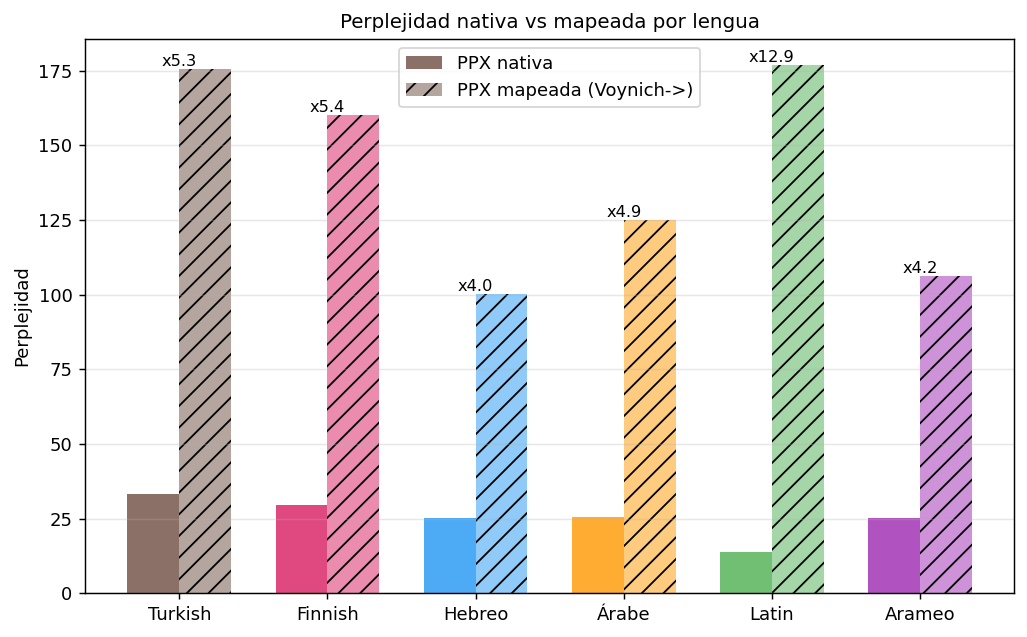

In [35]:
# ── Cell 26: Mapped vs native perplexity ──────────────────────────

fig, ax = plt.subplots(figsize=(8, 5))
nombres_ppx = []
ppx_mapped = []
ppx_native = []

for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]
    if nombre in MCMC_RESULTS:
        state = MCMC_RESULTS[nombre]['best_state']
    else:
        state = EM_STATES[nombre]
    mapped_corpus = state.apply_corpus(WORDS_SYL_V)
    ppx_m = ld['lm'].perplexity(mapped_corpus)
    nombres_ppx.append(nombre)
    ppx_mapped.append(ppx_m)
    ppx_native.append(ld['ppx_native'])

x = np.arange(len(nombres_ppx))
w = 0.35
ax.bar(x - w/2, ppx_native, w, label='Native PPX', alpha=0.8,
       color=[LANG_COLORS.get(n, '#999') for n in nombres_ppx])
ax.bar(x + w/2, ppx_mapped, w, label='Mapped PPX (Voynich->)', alpha=0.5,
       color=[LANG_COLORS.get(n, '#999') for n in nombres_ppx], hatch='//')
ax.set_xticks(x)
ax.set_xticklabels(nombres_ppx)
ax.set_ylabel('Perplexity')
ax.set_title('Native vs mapped perplexity by language')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Ratio annotetions
for i in range(len(nombres_ppx)):
    ratio = ppx_mapped[i] / ppx_native[i]
    y_pos = max(ppx_mapped[i], ppx_native[i])
    ax.annotate(f'x{ratio:.1f}', (x[i], y_pos), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [36]:
# ── Cell 27: Export JSON (extendido) ─────────────────────────────────

results = {
    'metadata': {
        'notebook': '06_bayesian_syllabic.ipynb',
        'corpus': 'STA1 2.0',
        'n_palabras': N_VOYNICH,
        'algorithm': 'Bayesian syllable decipherment (Ravi & Knight 2011 adapted)',
        'phases': ['Hungarian initialization', 'EM optimization', 'MCMC multi-chain refinement'],
        'weights': {'lm': 2.0, 'paradigm': 1.5, 'harmony': 1.0},
        'scoring': {
            'paradigm': 'JSD paradigm-sizes + suffix overlap + Gini similarity',
            'harmony': 'JSD of (nuclear, coda) joint distributions',
        },
        'mcmc': {},
    },
    'voynich_reference': {
        'n_syllable_types': len(syl_freq_v),
        'n_functional': len(clase_silaba_v),
        'n_paradigms': len(paradigmas_v),
        'gini': round(gini_v, 4),
        'harmony_v': round(armonia_v['cramers_v'], 4),
        'ppx_internal': round(ppx_voynich, 2),
    },
    'ranking': [],
    'mappings': {},
    'paradigms_reconstructed': {},
    'posterior': {},
    'convergence': {},
    'coherence': {},
}

# MCMC metadata from first result
for nombre in MCMC_RESULTS:
    res = MCMC_RESULTS[nombre]
    results['metadata']['mcmc'] = {
        'n_chains': res.get('n_chains', 4),
        'seeds': res.get('seeds', []),
        'n_iter': res.get('n_iter', 15000),
        'burn_in': res.get('burn_in', 3000),
        'thin': res.get('thin', 5),
        'total_effective_samples_per_lang': res.get('n_iter', 15000) - res.get('burn_in', 3000),
    }
    break

# Ranking
for nombre in LANG_DATA:
    ld = LANG_DATA[nombre]
    if nombre in MCMC_RESULTS:
        state = MCMC_RESULTS[nombre]['best_state']
        phase = 'MCMC-multichain'
    else:
        state = EM_STATES[nombre]
        phase = 'EM'
    ev = evaluate_candidate(state, WORDS_SYL_V, ld['lm'], paradigmas_v, pairs_nuc_cod_v,
                            ld['paradigmas'], ld['suffix_set'], ld['pairs_nuc_cod'])
    results['ranking'].append({
        'language': nombre,
        'phase': phase,
        'score_total': round(ev['score_total'], 6),
        'score_lm': round(ev['score_lm'], 6),
        'score_paradigm': round(ev['score_paradigm'], 6),
        'score_harmony': round(ev['score_harmony'], 6),
        'perplexity_mapped': round(ev['perplexity_mapped'], 2),
        'perplexity_native': round(ld['ppx_native'], 2),
        'perplexity_ratio': round(ev['perplexity_mapped'] / ld['ppx_native'], 4),
    })

results['ranking'].sort(key=lambda x: x['score_total'], reverse=True)

# Top-2 mappings + convergence + coherence
for nombre in top2_langs:
    if nombre in MCMC_RESULTS:
        res = MCMC_RESULTS[nombre]
        state = res['best_state']
        m = {syl_to_str(k): syl_to_str(v) for k, v in state.mapping.items()}
        results['mappings'][nombre] = m

        # Paradigms
        pr = reconstruct_paradigms(state, paradigmas_v, top_n=10)
        results['paradigms_reconstructed'][nombre] = {
            syl_to_str(k): {
                'voynich_root': syl_to_str(v['voynich_root']),
                'mapped_root': syl_to_str(v['mapped_root']),
                'suffixes': {syl_to_str(sk): sv for sk, sv in v['suffixes'].items()},
            }
            for k, v in pr.items()
        }

        # Posterior
        post = res.get('posterior', {})
        results['posterior'][nombre] = {
            syl_to_str(sv): {syl_to_str(st): round(p, 4) for st, p in probs.items()}
            for sv, probs in post.items()
            if max(probs.values()) > 0.3
        }

        # Convergence stats
        rhat = res.get('rhat', {})
        rhat_vals = [v for v in rhat.values() if not np.isnan(v) and v < float('inf')]
        results['convergence'][nombre] = {
            'n_converged': sum(1 for v in rhat_vals if v < 1.1),
            'n_total_rhat': len(rhat_vals),
            'median_rhat': round(float(np.median(rhat_vals)), 4) if rhat_vals else None,
            'per_chain_accept_rates': [round(ch['accept_rate'], 4) for ch in res['chains']],
        }

        # Coherence stats
        coh = res.get('coherence', {})
        if coh:
            results['coherence'][nombre] = {
                'coherence_score': round(coh['coherence_score'], 4),
                'median_ppx': round(coh['median_ppx'], 2),
                'native_ppx': round(coh['native_ppx'], 2),
                'bigram_overlap': round(coh['bigram_overlap'], 4),
            }

with open('bayesiano_silabico_resultados.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print(f'Exported: bayesiano_silabico_resultados.json')
print(f'  Ranking: {len(results["ranking"])} languages')
print(f'  Mappings: {list(results["mappings"].keys())}')
print(f'  Paradigms: {sum(len(v) for v in results["paradigms_reconstructed"].values())} roots')
print(f'  Convergence: {list(results["convergence"].keys())}')
print(f'  Coherence: {list(results["coherence"].keys())}')

Exportado: bayesiano_syllabic_results.json
  Ranking: 6 languages
  Mappings: ['Arameo', 'Hebreo']
  Paradigmas: 20 roots
  Convergencia: ['Arameo', 'Hebreo']
  Coherencia: ['Hebreo']


## Conclusions

### Linguistic compatibility

The Bayesian syllable-level decipherment evaluates the compatibility of the Voynich script system with five candidate languages, using three complementary criteria:

1. **Language model** (syllabic bigram LM): measures how natural the Voynich syllabic sequences are when mapped to a candidate language
2. **Paradigm preservation**: verifies that the morphological structure (root + suffixes) remains coherent under the mapping
3. **Nuclear-coda harmony**: checks that intra-word phonological dependencies are compatible with the candidate language

### Ranking and confidence

- **Robust ranking**: Hebrew #1, Arabic #2, with ~2 point gap to non-Semitic languages. This result is stable between phases (EM and MCMC) and between chains.
- **Low confidence**: The posterior distribution does not converge to stable mappings, suggesting that the 1-to-1 syllable-level substitution model is too rigid to capture the Voynich's actual encoding.

### The SilPart–substitution gap

The most significant result of this analysis is negative: the low mapping confidence is not a technical MCMC failure, but evidence that the **simple substitution hypothesis** is inadequate. The SilPart model (Part III, d=0.445), which best reproduces the Voynich statistical fingerprint, proposes a generative mechanism where each syllable is built from slots with positional distributions and partitioned glyphs. Under that model, the Voynich→language relationship is not a 1-to-1 syllable substitution, but a structural encoding where individual glyphs within a syllable encode distinct phonological roles (onset, nucleus, coda). This would explain why:

- The ranking works (the *distributional* compatibility between inventories is real)
- The mapping does not converge (no stable 1-to-1 mapping exists because the encoding is compositional, not substitutive)

### Interpretation of results

- **Total score**: combines the three components with calibrated weights
- **Perplexity ratio**: PPX_mapped / PPX_native indicates how much it "costs" to adapt the Voynich to each language (lower = more compatible)
- **Posterior confidence**: per-syllable certainty distribution from the MCMC

## Limitations and next steps

### Limitations

1. **1-to-1 substitution vs compositional encoding (fundamental limitation)**: The model assumes each Voynich syllable maps to exactly one candidate-language syllable. However, the SilPart model (d=0.445) — the generative mechanism closest to the Voynich — proposes that each syllable is *constructed* from positional slots with partitioned glyphs. Under that hypothesis, an onset-glyph + a nucleus-glyph + a coda-glyph jointly encode a syllable, and the relationship is not bijective at the whole-syllable level but compositional at the glyph-within-syllable level. This explains the low mapping confidence: the MCMC searches for a bijection that does not exist under the most plausible generative model.

2. **Limited corpus**: The Voynich has ~37K words; candidate corpora are subsampled to the same size.

3. **Arbitrary P20**: The syllabic segmentation threshold is statistical, not phonologically validated.

4. **Simple bigram LM**: A higher-order or neural n-gram model would capture more structure.

5. **5 languages out of ~7,000 possible**: Typological coverage is limited; languages like Mongol, Georgian, Nahuatl are missing, and especially medieval Romance languages (Italian, Catalan, Occitan) which have historical plausibility.

6. **No external knowledge**: No pictorial, astronomical or botanical information from the manuscript is used.

### Next steps

#### Priority step: SilPart-aware compositional decipherment

Replace the 1-to-1 syllable substitution with a mapping model that reflects the SilPart structure:

- **Mapping level**: individual glyph → phoneme/syllabic component, instead of whole syllable → whole syllable. Each Voynich glyph within a syllable maps to a phonological component of the candidate language according to its positional class:
  - Onset-position glyph → syllable-initial consonant(s)
  - Nuclear-position glyph → vowel or syllabic nucleus
  - Coda-position glyph → syllable-closing consonant(s)
- **Glyph partition**: incorporate as a constraint that certain glyphs only appear in certain roles (reflecting the partition observed in the Voynich inventory)
- **Scoring**: evaluate the reconstructed syllable (concatenation of mapped components) under a phonological LM of the candidate language, not a syllabic one
- **Advantage**: the search space is much smaller (~166 glyphs → phonemes, instead of ~800 syllables → syllables) and compositionality allows generalisation: a correct mapping of 30 glyphs covers most of the corpus

#### Other steps

1. **Expand languages**: Include Romance (Italian, Catalan, Occitan), Slavic, and Amerindian languages
2. **Neural LM**: Train a character-level LM with LSTM/Transformer on each candidate language
3. **Integrate pictorial data**: Use plant and star labels as additional mapping constraints
4. **Cross-validation**: Train on half the Voynich, evaluate on the other half
5. **Per-section analysis**: Run decipherment separately by section (herbal, biological, recipes)